# 04 · Voxel size and parameter sensitivity

This notebook shows the evidence for three review comments on subsection 3.2.2:

- the requested comparison of voxel sizes from 5 to 25 cm;
- the 0.30 m matching radius;
- the height-prior weights, `min_conf` and `min_flip_ratio`.

The write-up is [`README_parameter_sensitivity.md`](../README_parameter_sensitivity.md). It covers
what each parameter does, draft replies, and the findings to settle before replying.

Every table here is generated from `assets/parameter_sensitivity/parameter_sensitivity_per_tile.csv`,
which `parameter_sensitivity.py` writes. No number is typed by hand. The two voxel drawings in
section 2 read the lidar tiles directly.

> This notebook used to hold a site-1 sweep of the pipeline's own counters
> (`compare_voxel_sizes.py`, `assets/data_voxels*`) and draft reviewer text built on it. Both are
> superseded. Counters that rise or fall with voxel size cannot pick one size over another, and
> the old reading of Stage 4 does not survive the full sweep (see the README's findings). The
> earlier version is in git history (`ff35218`).

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display


def find_step_dir(start: Path) -> Path:
    relative = Path("phase_4_3D_lidar_prep/step_3_structure_class")
    for candidate in [start, *start.parents]:
        if (candidate / relative / "parameter_sensitivity.py").exists():
            return candidate / relative
    raise FileNotFoundError(f"Could not locate step_3_structure_class from {start}")


STEP_DIR = find_step_dir(Path.cwd().resolve())
if str(STEP_DIR) not in sys.path:
    sys.path.insert(0, str(STEP_DIR))

import compare_voxel_sizes as cvs
import parameter_sensitivity as ps
import plot_parameter_sensitivity as pps
import plot_voxel_transfer as pvt

ASSETS = STEP_DIR / "assets" / "parameter_sensitivity"
DATA_ROOT = ps.DATA_ROOT  # the lidar tiles, read only by the drawings in section 2
per_tile = pd.read_csv(ASSETS / "parameter_sensitivity_per_tile.csv")

swept = per_tile[per_tile["Parameter"] != "input"]
display(swept.groupby(["Parameter", "Site condition"])["Tile"].nunique().unstack()
        .rename_axis(columns="Tiles per site"))

Tiles per site,Low,Medium
Parameter,,
height_match_radius,15,15
height_prior_out_of_range_weight,15,15
min_conf,15,15
min_flip_ratio,15,15
voxel_size,15,15


## 0. The answer in brief

Each parameter was varied on its own across its range while the others stayed at their defaults,
on all 30 tiles. The last two columns give the largest change any tested value made to the final
labels, on any tile.

Only voxel size matters. The matching radius is never reached, and the three Stage-4 parameters
act inside mallee crowns that Stage 5 then turns wholly to mallee. Sections 1–3 show why.


In [2]:
display(Markdown(pps.answer_table(per_tile)))


| Parameter | Default | What it decides | Values tested | Medium: largest change (%) | Low: largest change (%) |
|---|---:|---|---|---:|---:|
| Voxel size | 10 cm | how far a 2D label extends to neighbouring returns | 5, 10, 15, 20, 25 | 9.24 | 16.28 |
| Matching radius | 0.3 m | how far a point may look for its height above ground | 0.01, 0.05, 0.1, 0.3, 1 | 0.00 | 0.00 |
| Out-of-range weight | 0.1 | how strongly a class outside its height range is penalised | 1, 0.5, 0.1, 0.01, 0 | 0.00 | 0.13 |
| min_conf | 0.3 | whether an unlabelled point inside a crown is filled | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.00 | 0.00 |
| min_flip_ratio | 1.5 | whether an existing label is overturned | 1, 1.25, 1.5, 2, 3 | 0.00 | 0.02 |

## 1. What the pipeline is given

The structure cloud holds the lidar returns that carry a 2D label. It is cut from the Z_norm cloud
with PDAL `filters.colorization`: each return takes the class of the 5 cm label cell beneath it.
`parameter_sensitivity.py` confirms this on every tile. It also bounds the only approximation in
Stage 1's height lookup.

In [3]:
display(Markdown(pps.input_table(per_tile)))

| Check | Medium | Low |
|---|---:|---:|
| Tiles | 15 | 15 |
| Structure points with an exact Z_norm twin, lowest tile (%) | 100.000 | 100.000 |
| Largest XY match distance, any tile (m) | 0.000 | 0.000 |
| Structure points beyond the 0.30 m radius, any tile (%) | 0.000 | 0.000 |
| Heights taken from another return in the same column, range over tiles (%) | 8.3–19.1 | 4.3–10.5 |
| Largest class-range shift that causes, any tile (m) | 0.017 | 0.003 |
| Lidar points on labelled 5 cm cells missing from the structure cloud, all tiles | 362 (0.005%) | 0 (0.000%) |
| Plan-view mIoU of the 5 cm labels themselves (mean / median) | 0.925 / 0.953 | 0.884 / 0.899 |
| 5 cm labels lying outside the 1 cm footprint (mean / median, %) | 8.4 / 9.0 | 2.5 / 2.5 |
| Crown detection in the sweep (as the delivered labels were made) | `auto` | defaults |
| `auto` resolves to (min_tree_dist / smoothing_sigma), tiles | 0.8 m / 1.33 px on 15 | 0.8 m / 1.33 px on 4; 1.5 m / 1.00 px on 11 |
| Canopy point spacing `auto` starts from, range over tiles (m) | 0.022–0.032 | 0.010–0.022 |

## 2. Voxel size

### 2.1 The supplementary figure

Lines are medians across each site's tiles, with the inter-quartile range shaded. Panels (a)–(e)
describe the Stage-2 transfer itself and panel (f) the final labels. The tables give
`mean / median`.

Wrote: /home/uqlsoto1/code_phd/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/assets/parameter_sensitivity/supplementary_voxel_size_sensitivity.png (+ .pdf)


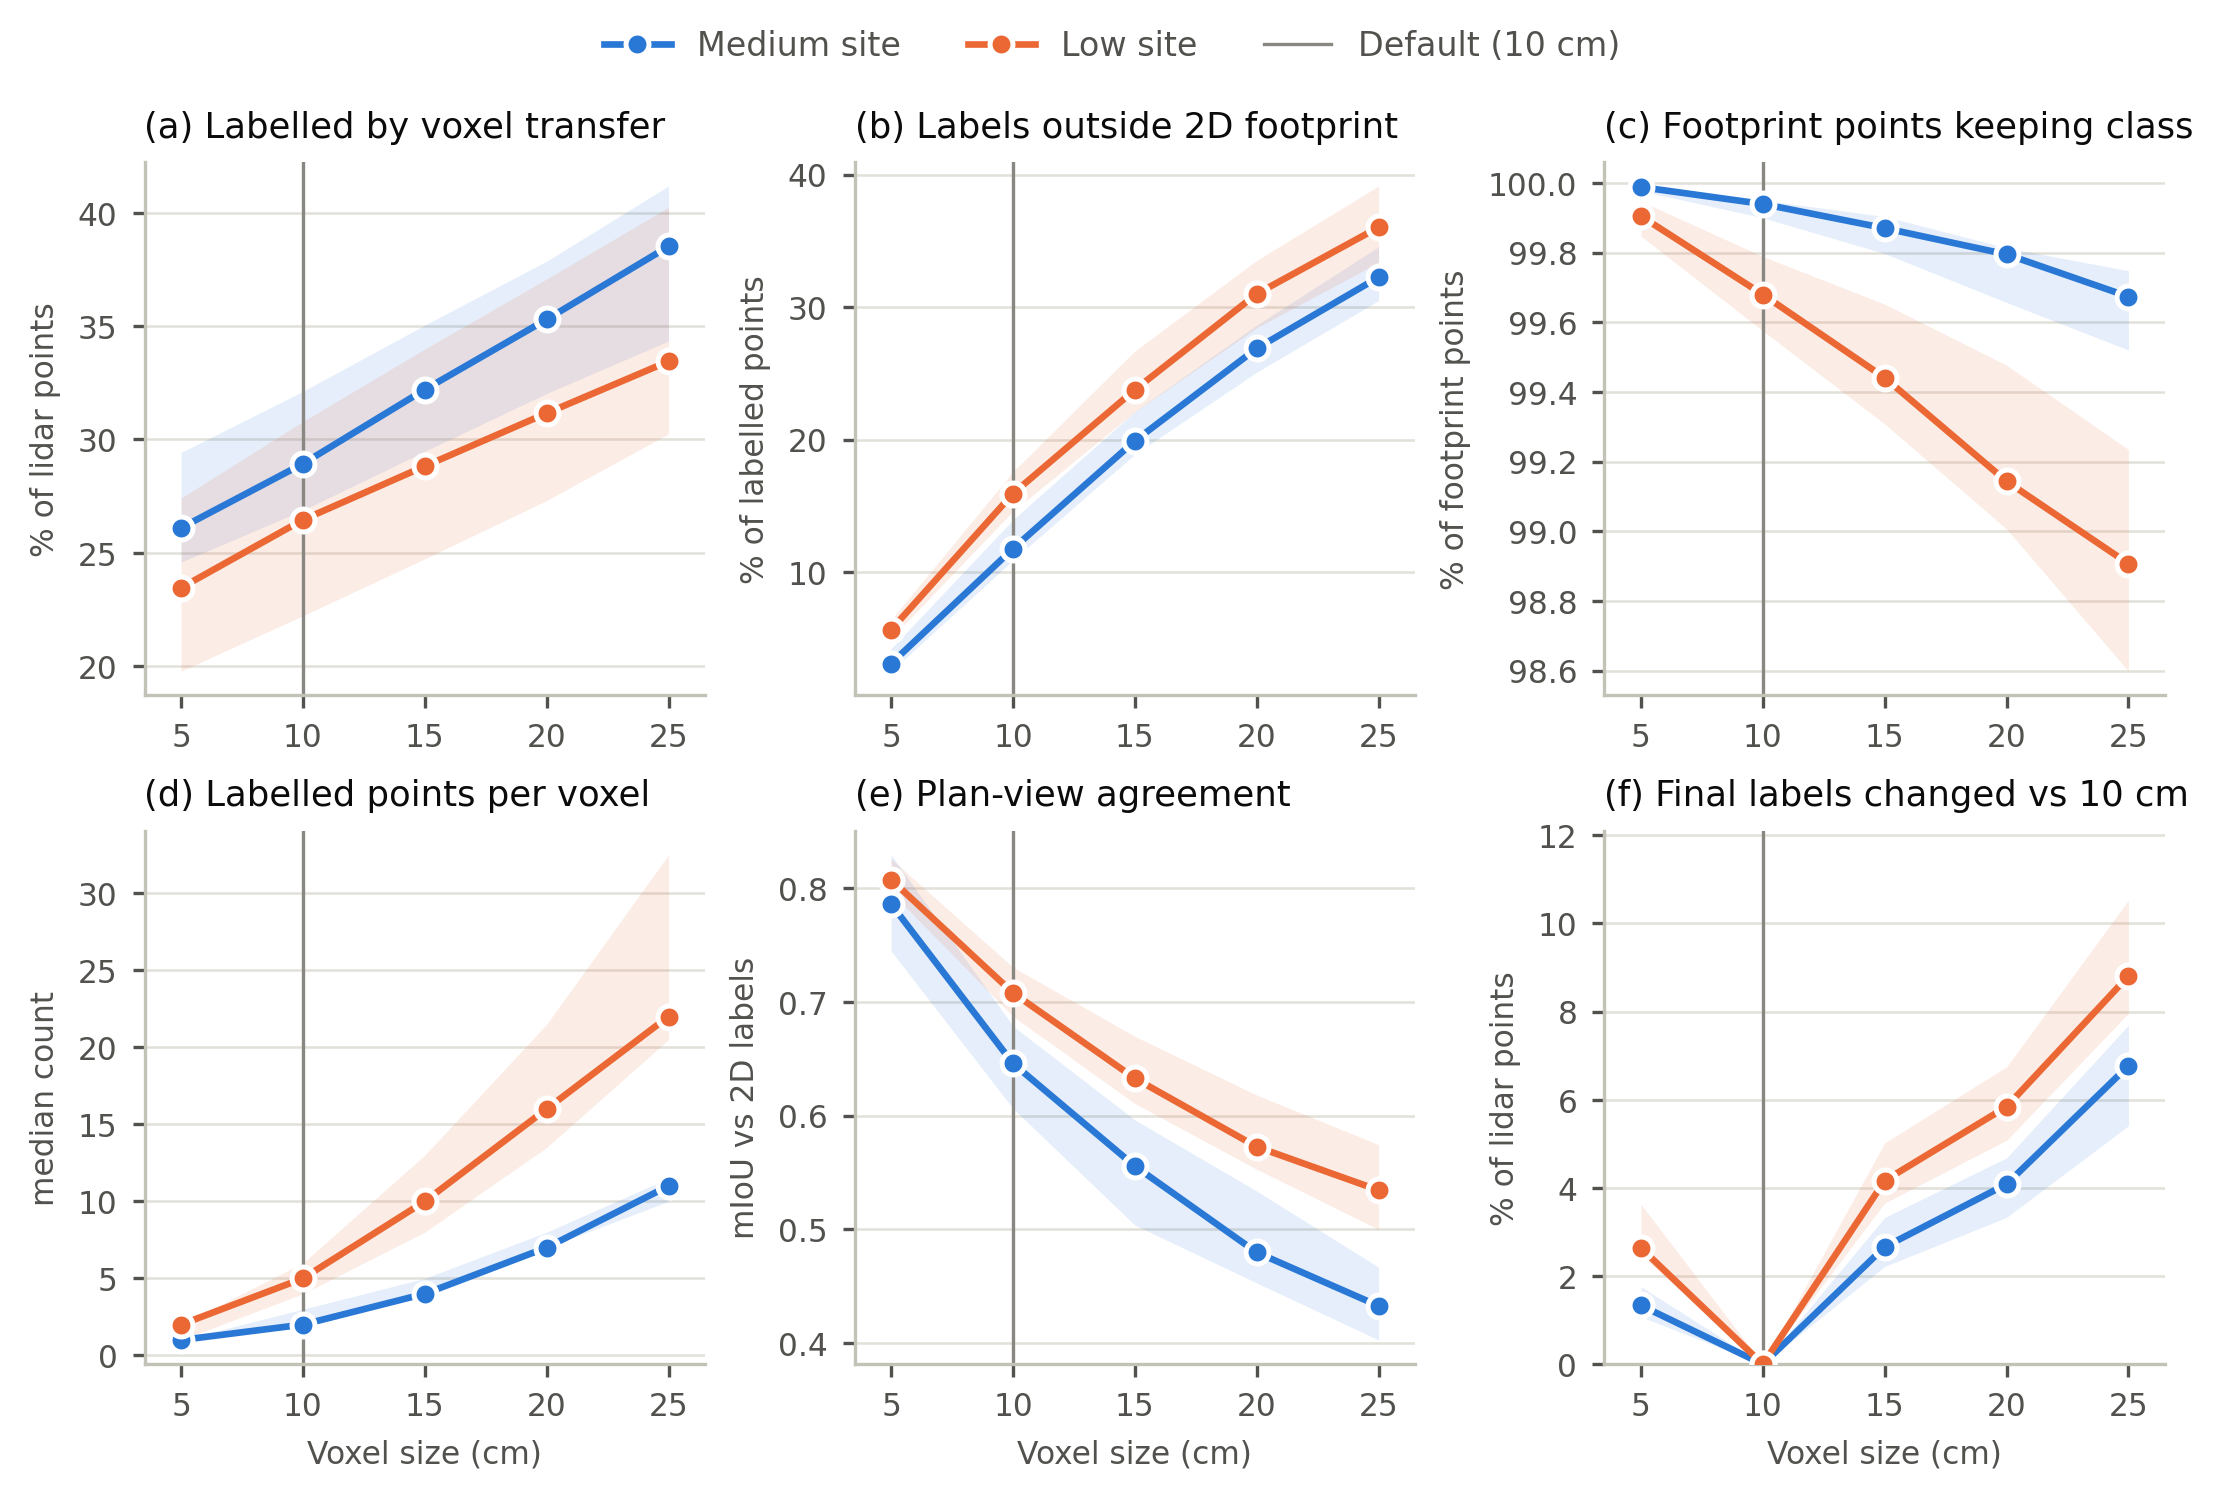

In [4]:
pps.plot_voxel_figure(per_tile, ASSETS / "supplementary_voxel_size_sensitivity")
display(Image(filename=str(ASSETS / "supplementary_voxel_size_sensitivity.png")))

In [5]:
display(Markdown("**The transfer (Stage 2)**\n\n"
                 + pps.table(per_tile, "voxel_size", pps.TRANSFER_COLUMNS)
                 + "\n\n" + pps.voxel_extremes(per_tile)))
display(Markdown("**The final labels (after Stages 3–5)**\n\n"
                 + pps.table(per_tile, "voxel_size", pps.FINAL_COLUMNS)))

**The transfer (Stage 2)**

| Site | Voxel size (cm) | Labelled by transfer (%) | Outside footprint (%) | Footprint recall (%) | mIoU vs 5 cm input | Points per voxel | Single-point voxels (%) | Mixed-class voxels (%) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Medium | 5 | 27.2 / 26.1 | 3.5 / 3.1 | 99.97 / 99.99 | 0.787 / 0.786 | 1.0 / 1.0 | 67.2 / 69.3 | 0.04 / 0.02 |
| Medium | **10** | 30.0 / 28.9 | 12.5 / 11.8 | 99.89 / 99.94 | 0.648 / 0.646 | 2.3 / 2.0 | 33.9 / 35.2 | 0.24 / 0.14 |
| Medium | 15 | 33.0 / 32.2 | 20.6 / 19.9 | 99.80 / 99.87 | 0.556 / 0.556 | 4.4 / 4.0 | 20.4 / 20.7 | 0.59 / 0.39 |
| Medium | 20 | 35.9 / 35.3 | 27.0 / 26.9 | 99.69 / 99.80 | 0.495 / 0.480 | 7.6 / 7.0 | 14.7 / 15.1 | 1.04 / 0.78 |
| Medium | 25 | 38.8 / 38.5 | 32.5 / 32.3 | 99.57 / 99.67 | 0.446 / 0.433 | 11.6 / 11.0 | 11.6 / 11.7 | 1.64 / 1.29 |
| Low | 5 | 24.4 / 23.5 | 5.7 / 5.6 | 99.88 / 99.90 | 0.787 / 0.808 | 1.5 / 2.0 | 48.3 / 46.7 | 0.20 / 0.17 |
| Low | **10** | 27.4 / 26.4 | 16.0 / 15.9 | 99.68 / 99.68 | 0.692 / 0.708 | 5.0 / 5.0 | 17.6 / 16.8 | 0.92 / 0.84 |
| Low | 15 | 30.4 / 28.8 | 24.2 / 23.8 | 99.45 / 99.44 | 0.624 / 0.633 | 10.5 / 10.0 | 11.0 / 11.3 | 1.85 / 1.82 |
| Low | 20 | 33.3 / 31.2 | 30.8 / 31.0 | 99.21 / 99.14 | 0.572 / 0.572 | 17.2 / 16.0 | 8.4 / 8.3 | 2.80 / 2.74 |
| Low | 25 | 36.1 / 33.4 | 36.2 / 36.0 | 98.92 / 98.91 | 0.526 / 0.534 | 25.6 / 22.0 | 7.1 / 6.9 | 3.81 / 3.79 |

- Medium site: footprint recall on the lowest tile at any voxel size **98.82%**; at 5 cm the per-tile median of labelled points per voxel ranges 1–1.
- Low site: footprint recall on the lowest tile at any voxel size **97.73%**; at 5 cm the per-tile median of labelled points per voxel ranges 1–2.

**The final labels (after Stages 3–5)**

| Site | Voxel size (cm) | Labelled (%) | Outside footprint (%) | mIoU vs 5 cm input | mIoU vs 1 cm | Changed from 10 cm (%) |
|---|---:|---:|---:|---:|---:|---:|
| Medium | 5 | 28.8 / 28.2 | 14.5 / 15.3 | 0.550 / 0.539 | 0.460 / 0.466 | 1.43 / 1.33 |
| Medium | **10** | 30.3 / 29.9 | 18.5 / 18.4 | 0.472 / 0.478 | 0.402 / 0.400 | 0.00 / 0.00 |
| Medium | 15 | 32.2 / 32.0 | 23.4 / 23.6 | 0.413 / 0.412 | 0.357 / 0.359 | 2.74 / 2.66 |
| Medium | 20 | 34.2 / 34.2 | 27.9 / 27.9 | 0.374 / 0.380 | 0.325 / 0.326 | 4.03 / 4.09 |
| Medium | 25 | 36.4 / 36.8 | 32.2 / 32.5 | 0.340 / 0.346 | 0.299 / 0.297 | 6.63 / 6.77 |
| Low | 5 | 24.4 / 23.5 | 6.0 / 5.8 | 0.713 / 0.796 | 0.712 / 0.795 | 3.09 / 2.64 |
| Low | **10** | 27.4 / 26.6 | 16.2 / 16.1 | 0.632 / 0.700 | 0.631 / 0.700 | 0.00 / 0.00 |
| Low | 15 | 30.4 / 29.0 | 24.3 / 23.8 | 0.572 / 0.623 | 0.571 / 0.622 | 4.49 / 4.17 |
| Low | 20 | 33.2 / 31.3 | 30.9 / 31.0 | 0.523 / 0.560 | 0.523 / 0.559 | 6.09 / 5.84 |
| Low | 25 | 36.1 / 33.5 | 36.2 / 36.0 | 0.482 / 0.502 | 0.482 / 0.502 | 9.62 / 8.81 |

### 2.2 What voxel size does to the labels

The figure above counts the labels spread past their 2D footprint; this one draws them. It shows a
2 m window of one tile, with every lidar return seen from above:

- **blue:** the return carries a label on a cell the 2D labels also label;
- **orange:** the transfer gave it a label on a cell the 2D labels leave unlabelled;
- **grey:** the return is unlabelled.

The black outline is the 2D footprint, and the grey lines are the voxel grid at each size. Every
orange label can be traced to a voxel it shares with a labelled return.

Two cautions for reading it:

- **Grid squares are voxel columns.** A return takes a label only from labelled returns in the
  same voxel, which also means at the same height. A grey return can therefore share a square with
  blue ones.
- **The window is chosen, not typical.** It is the window with the most spread labels at 25 cm,
  among windows a quarter to three quarters labelled. Its percentages therefore run higher than
  the site means in 2.1.

Wrote: /home/uqlsoto1/code_phd/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/assets/parameter_sensitivity/voxel_transfer_tile106.png (+ .pdf); window lower-left (461693.97, 6237524.95), 2 m


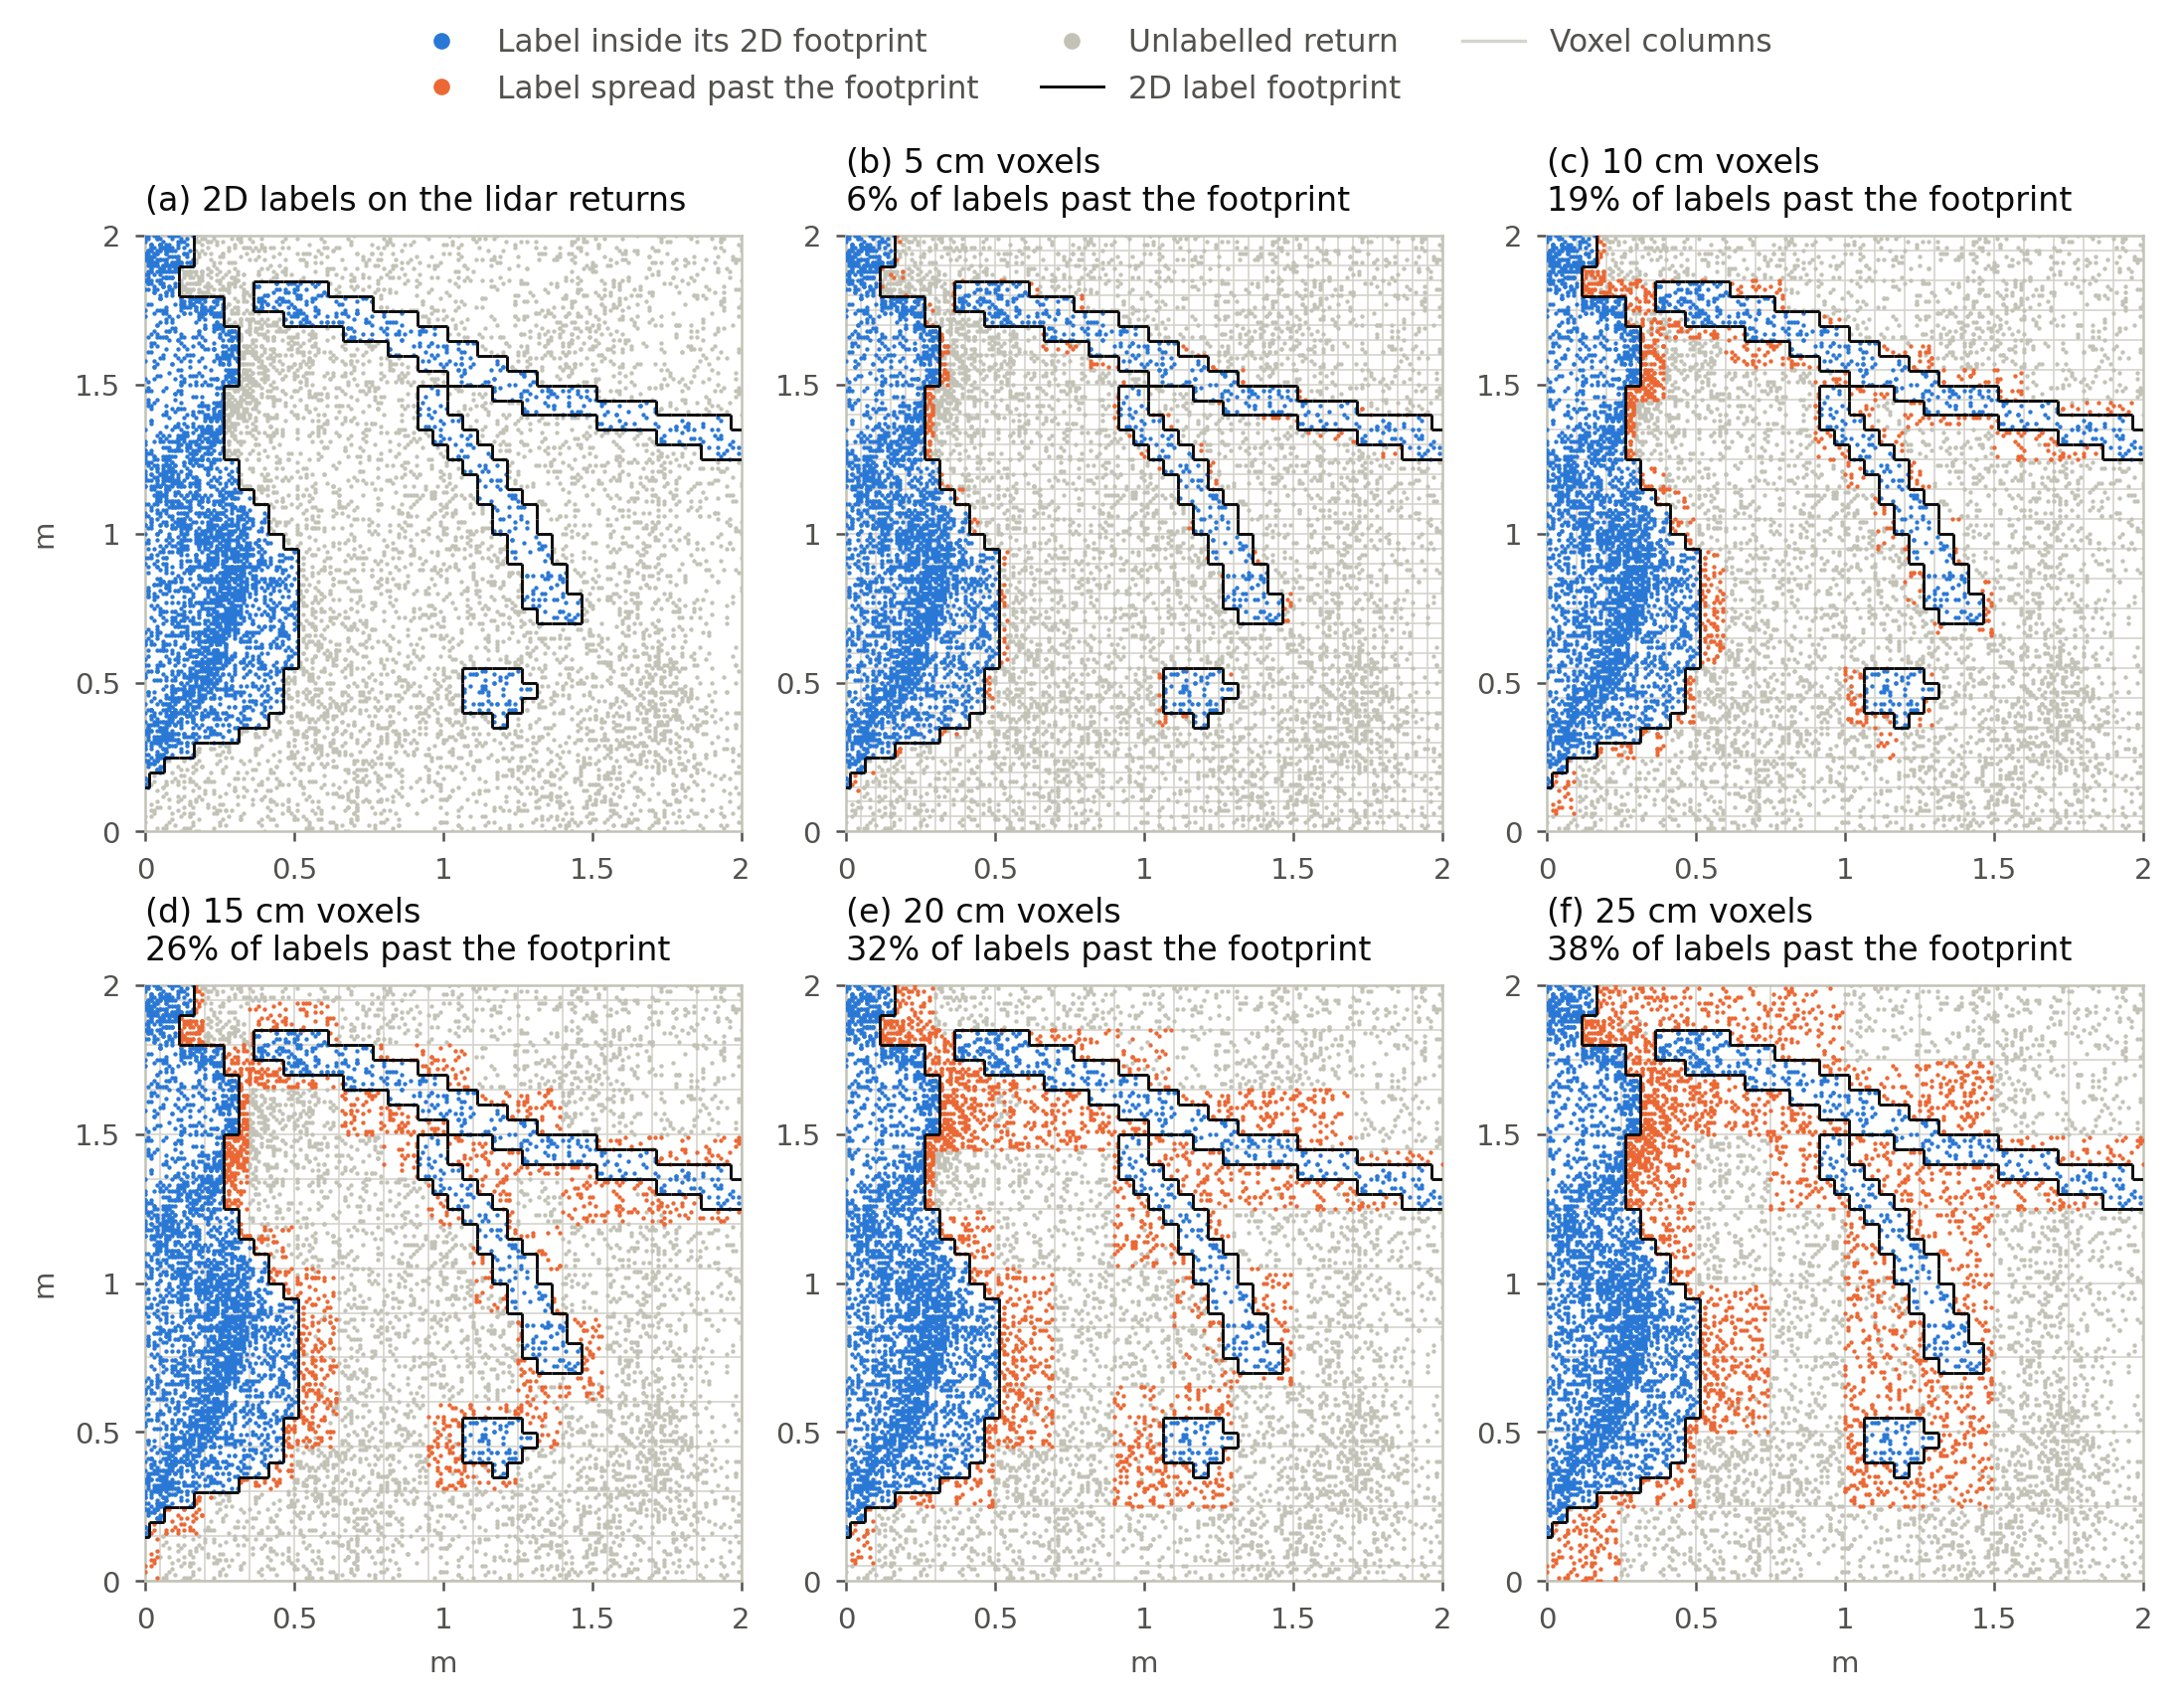

In [6]:
SITE, TILE = "site1_1_DD0001", "106"
transfer_figure = ASSETS / f"voxel_transfer_tile{TILE}.png"
if (DATA_ROOT / SITE).exists():
    pvt.plot_tile(DATA_ROOT, SITE, TILE, transfer_figure.with_suffix(""))
else:
    print(f"{DATA_ROOT / SITE} is not available here; showing the saved figure.")
display(Image(filename=str(transfer_figure)))

### 2.3 The voxels in 3D

This is the same tile divided into voxels at each size, drawn in 3D by
`compare_voxel_sizes.plot_las_3d_voxel_sweep` and coloured by how many returns each voxel holds.

It shows geometry only: how coarse each grid is, not what happens to the labels. It also draws a
random sample of the tile's returns, so its voxel counts describe that sample rather than the
whole tile.

Wrote: /home/uqlsoto1/code_phd/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/assets/parameter_sensitivity/tile_106_3d_voxel_sweep.png


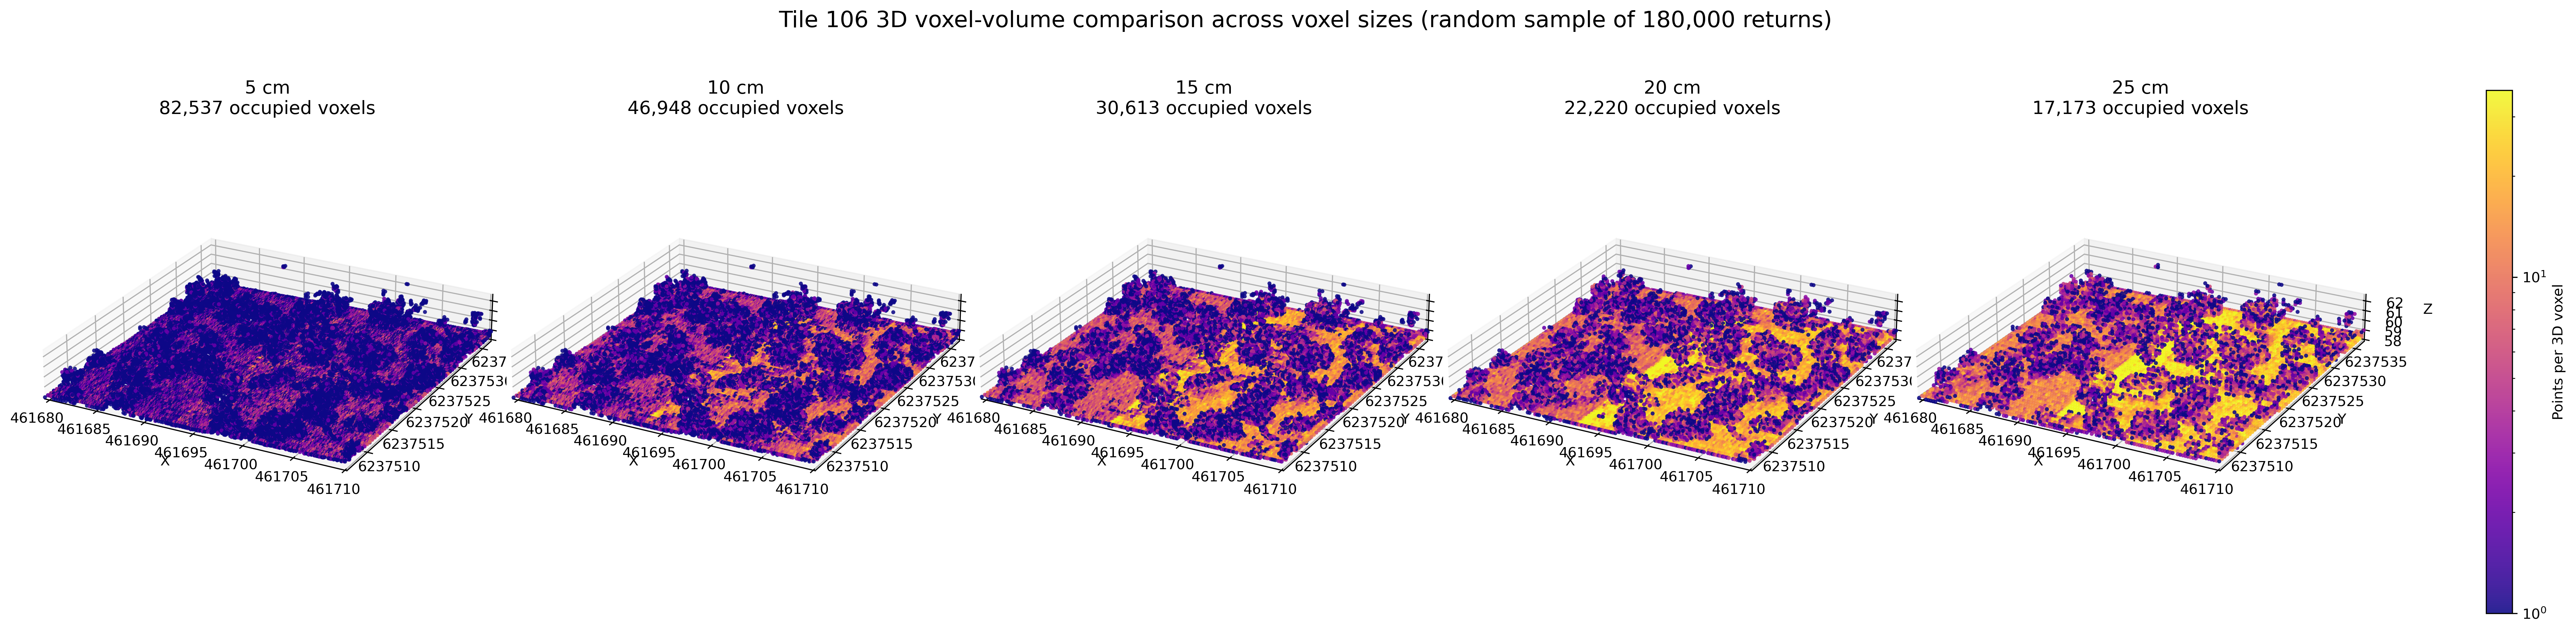

In [7]:
volume_figure = ASSETS / f"tile_{TILE}_3d_voxel_sweep.png"
if (DATA_ROOT / SITE).exists():
    z_path = DATA_ROOT / SITE / ps.Z_NORM_DIR / f"z_norm_csf_tiles_multispectral.{TILE}.las"
    cvs.plot_las_3d_voxel_sweep(z_path, volume_figure, TILE, list(ps.SWEEPS["voxel_size"]))
else:
    print(f"{DATA_ROOT / SITE} is not available here; showing the saved figure.")
display(Image(filename=str(volume_figure)))

### 2.4 Point density, and what a larger voxel buys

Sections 2.1–2.3 show that agreement with the 2D labels falls monotonically with voxel size, so
they cannot pick a size. This section asks the two questions that can: **how densely do the
labelled returns fill the grid**, and **what does each step up in voxel size actually add**.

The first table is density. A voxel holding a single labelled return has nothing to merge, so
the transfer there reduces to copying the 2D raster onto that point.

The second table puts coverage and spread on the same base. `Outside footprint` is normally a
share of *labelled* points, so it is converted back to a share of all lidar points before
differencing; the last column is the share of the **additional** labels that land on cells the
2D annotation leaves unlabelled.


In [8]:
display(Markdown("**Point density in the voxel grid**\n\n"
                 + pps.table(per_tile, "voxel_size", pps.DENSITY_COLUMNS)))
display(Markdown("**What a larger voxel buys and costs**\n\n"
                 + pps.coverage_cost_table(per_tile)))


**Point density in the voxel grid**

| Site | Voxel size (cm) | Occupied voxels | Labelled points per voxel | Single-point voxels (%) | Mixed-class voxels (%) | Footprint recall (%) |
|---|---:|---:|---:|---:|---:|---:|
| Medium | 5 | 276484 / 260169 | 1.0 / 1.0 | 67.2 / 69.3 | 0.04 / 0.02 | 99.97 / 99.99 |
| Medium | **10** | 114032 / 113615 | 2.3 / 2.0 | 33.9 / 35.2 | 0.24 / 0.14 | 99.89 / 99.94 |
| Medium | 15 | 55130 / 56018 | 4.4 / 4.0 | 20.4 / 20.7 | 0.59 / 0.39 | 99.80 / 99.87 |
| Medium | 20 | 31523 / 31400 | 7.6 / 7.0 | 14.7 / 15.1 | 1.04 / 0.78 | 99.69 / 99.80 |
| Medium | 25 | 20211 / 19954 | 11.6 / 11.0 | 11.6 / 11.7 | 1.64 / 1.29 | 99.57 / 99.67 |
| Low | 5 | 134462 / 129749 | 1.5 / 2.0 | 48.3 / 46.7 | 0.20 / 0.17 | 99.88 / 99.90 |
| Low | **10** | 43085 / 42226 | 5.0 / 5.0 | 17.6 / 16.8 | 0.92 / 0.84 | 99.68 / 99.68 |
| Low | 15 | 20186 / 20006 | 10.5 / 10.0 | 11.0 / 11.3 | 1.85 / 1.82 | 99.45 / 99.44 |
| Low | 20 | 11971 / 12267 | 17.2 / 16.0 | 8.4 / 8.3 | 2.80 / 2.74 | 99.21 / 99.14 |
| Low | 25 | 7977 / 8031 | 25.6 / 22.0 | 7.1 / 6.9 | 3.81 / 3.79 | 98.92 / 98.91 |

**What a larger voxel buys and costs**

| Site | Voxel (cm) | Labelled (% of points) | Outside footprint (% of points) | Extra labelled vs 5 cm | Of which outside footprint |
|---|---:|---:|---:|---:|---:|
| Medium | 5 | 27.2 | 0.96 | +0.00 | – |
| Medium | **10** | 30.0 | 3.76 | +2.80 | 100% |
| Medium | 15 | 33.0 | 6.79 | +5.82 | 100% |
| Medium | 20 | 35.9 | 9.71 | +8.73 | 100% |
| Medium | 25 | 38.8 | 12.63 | +11.65 | 100% |
| Low | 5 | 24.4 | 1.40 | +0.00 | – |
| Low | **10** | 27.4 | 4.40 | +3.03 | 99% |
| Low | 15 | 30.4 | 7.38 | +6.03 | 99% |
| Low | 20 | 33.3 | 10.25 | +8.90 | 99% |
| Low | 25 | 36.1 | 13.08 | +11.73 | 100% |

**Reading.**

- **At 5 cm the transfer barely operates.** A voxel is one label cell and holds a median of one
  labelled return; 67% of Medium voxels and 48% of Low voxels hold exactly one. With nothing to
  merge, Stage 2 is close to projecting the 2D raster onto the points rather than propagating
  labels through 3D structure. At 10 cm the median rises to 2.3 (Medium) and 5.0 (Low), and
  single-point voxels fall to 34% and 18%.

- **Every extra label a larger voxel buys lands outside the 2D footprint.** Going from 5 to
  10 cm labels 2.8% (Medium) and 3.0% (Low) more of the lidar points, and **99–100% of those
  additional labels** sit on cells the annotation leaves unlabelled. The same holds at every
  further step. Enlarging the voxel adds nothing inside the footprints; it extends labels
  laterally.

- **So no measure anchored to the 2D labels prefers 10 cm.** Footprint recall is highest at
  5 cm (99.97% Medium, 99.88% Low) and falls monotonically. The case for 10 cm rests on the
  density argument above, not on fidelity to the 2D labels.

**The limit of this evidence.** "Outside footprint" is not the same as "wrong". The 2D polygons
are plan-view outlines with real delineation uncertainty — phase 3 measured a ±5 cm delineation
IoU of only 0.32 (Medium) and 0.51 (Low) — so a return just beyond a polygon edge may well belong
to that feature. With no independent 3D reference these measures cannot separate spread *error*
from legitimate recovery of a feature's true extent, and therefore cannot identify an optimum.


### 2.5 Where the density comes from: survey spacing and vertical structure

Section 2.4 shows *that* a 5 cm voxel usually holds one labelled return. This section shows
**why**, which turns the choice from an empirical one into a property of the survey.

**In plan.** Only about a quarter of returns carry a 2D label, so the spacing that matters is
that of the labelled returns, not of all returns. For a planimetric density $d$ returns per m²
the mean spacing is $1/\sqrt{d}$. The table below gives each tested voxel size as a multiple of
that spacing.

A voxel narrower than the spacing can only be expected to hold one labelled return, so the merge
has nothing to combine; roughly two spacings is the minimum for reliable co-occupancy.


In [9]:
display(Markdown("**Voxel size relative to the spacing of labelled returns**\n\n"
                 + pps.spacing_table(per_tile)))
display(Markdown("**How the voxel would scale with survey density**\n\n"
                 + pps.sensor_scaling_table(per_tile)))


**Voxel size relative to the spacing of labelled returns**

| Site | Labelled returns per m² | Mean spacing (cm) | 5 cm | 10 cm | 15 cm | 20 cm | 25 cm |
|---|---:|---:|---:|---:|---:|---:|---:|
| Medium | 493 | 4.51 | 1.11× | 2.22× | 3.33× | 4.44× | 5.55× |
| Low | 321 | 5.58 | 0.90× | 1.79× | 2.69× | 3.58× | 4.48× |

**How the voxel would scale with survey density**

| Survey density | Labelled spacing (cm) | Voxel at 2× spacing (cm) |
|---|---:|---:|
| half as dense (0.5×) | 6.4–7.9 | 13–16 |
| this survey (1×) | 4.5–5.6 | 9–11 |
| twice as dense (2×) | 3.2–3.9 | 6–8 |

**In height.** The spacing above is a plan-view average, and the voxel is a cube: two returns
one metre apart in height never share a 10 cm cube however close they are in plan. The profile
below counts returns per 10 cm height bin, as absolute numbers, from `vertical_profile.py`.

Counts span three orders of magnitude, so the axis is logarithmic; without it the ground return
at 0–10 cm is the only visible feature. Panel (c) shows the Medium site alone, since the two
sites carry different growth forms.


Wrote: /home/uqlsoto1/code_phd/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/assets/parameter_sensitivity/supplementary_vertical_profile.png (+ .pdf)


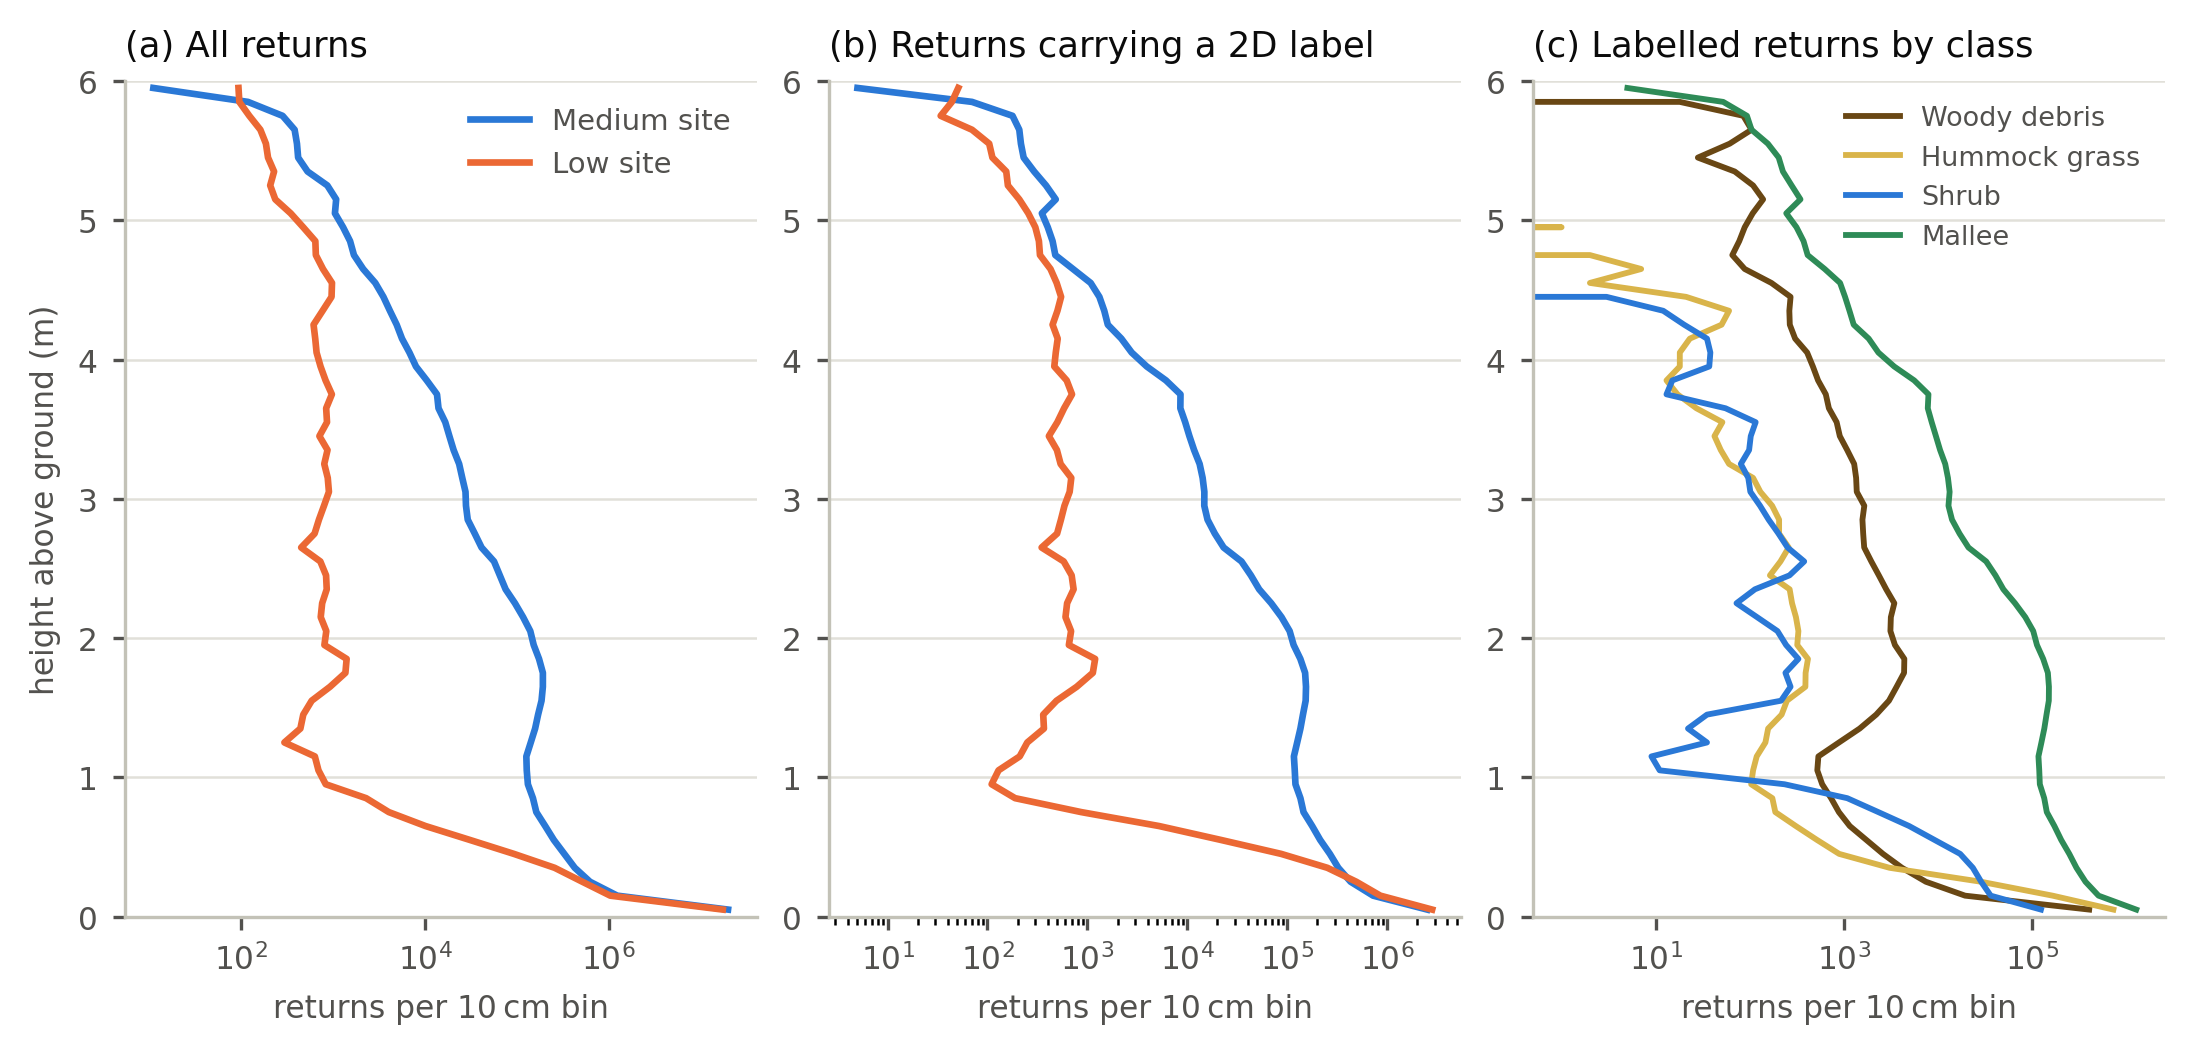

| Site | Band | All returns | Labelled returns | Labelled (%) | Labelled per m² |
|---|---|---:|---:|---:|---:|
| Medium | 0–10 cm (ground) | 19,939,976 | 2,511,074 | 12.6 | 177.4 |
| Medium | 10–50 cm (understorey) | 2,621,957 | 1,741,635 | 66.4 | 123.0 |
| Medium | 0.5–1.5 m | 1,625,540 | 1,430,794 | 88.0 | 101.1 |
| Medium | 1.5–3 m | 1,579,055 | 1,172,479 | 74.3 | 82.8 |
| Medium | >3 m (upper canopy) | 217,520 | 115,860 | 53.3 | 8.2 |
| Low | 0–10 cm (ground) | 17,496,215 | 2,812,597 | 16.1 | 198.7 |
| Low | 10–50 cm (understorey) | 1,907,211 | 1,681,147 | 88.1 | 118.8 |
| Low | 0.5–1.5 m | 50,606 | 29,369 | 58.0 | 2.1 |
| Low | 1.5–3 m | 12,374 | 10,143 | 82.0 | 0.7 |
| Low | >3 m (upper canopy) | 17,740 | 11,396 | 64.2 | 0.8 |

In [10]:
profile = pd.read_csv(ASSETS / "vertical_profile.csv")
pps.plot_vertical_profile(profile, ASSETS / "supplementary_vertical_profile")
display(Image(filename=str(ASSETS / "supplementary_vertical_profile.png")))
display(Markdown(pps.vertical_table(profile, pps.HEIGHT_BANDS)))


**Reading.**

- **The plan-view average hides a 60-fold range.** Labelled returns average 493 per m² at the
  Medium site, but that is dominated by the ground: above 3 m the site carries only ~8 labelled
  returns per m², a mean spacing of roughly 35 cm. A 10 cm voxel in the upper canopy will almost
  always hold a single labelled return, so the merge is weakest exactly where mallee sits.

- **The rule holds where the labels are.** Most labelled returns lie below 1.5 m (Medium: 5.7 M
  of 7.0 M; Low: 4.5 M of 4.5 M), and there the density gives a spacing of a few centimetres, so
  10 cm is comfortably above the two-spacing minimum.

- **The Low site is almost entirely low vegetation.** Above 0.5 m it holds 2.1 labelled returns
  per m², and above 1.5 m only 0.7. That is consistent with its 2D labels carrying no mallee, and
  with the watershed finding crowns on just 4 of its 15 tiles (section 3).

**Consequence for the choice.** No single voxel size satisfies the two-spacing rule at every
height. 10 cm meets it through the understorey, where the great majority of labelled returns lie,
and falls short of it in the upper canopy. A height-varying voxel would follow the density more
closely; that is a change to the method rather than a parameter value, and is not made here.


### 2.6 A limitation the profile exposes: the transfer is a vertical projection

The structure cloud is built by `maskclip/core.py` as

```text
filters.crop  →  filters.colorization (label raster → Classification)  →  filters.range [64:68]
```

`filters.colorization` is a **plan-view raster lookup with no height gate**: a return takes the
class of the 5 cm cell beneath it whatever its height. Every return in the air column above a
labelled cell therefore inherits that cell's class. Where a ground class lies under mallee
canopy, canopy returns are written with the ground class.

The height percentiles below show it. A clean class barely moves from p95 to p99; a contaminated
one jumps, because the contamination is a thin tail rather than a shift of the whole class.


In [11]:
display(Markdown(pps.class_height_table(profile)))


| Site | Class | Returns | p50 | p85 | p95 | p99 | Above 1 m |
|---|---|---:|---:|---:|---:|---:|---:|
| Medium | Woody debris | 497,779 | 0.05 m | 0.25 m | 2.35 m | 3.65 m | 11.9% |
| Medium | Hummock grass | 926,055 | 0.05 m | 0.15 m | 0.15 m | 0.35 m | 0.6% |
| Medium | Shrub | 249,675 | 0.15 m | 0.45 m | 0.65 m | 2.15 m | 1.6% |
| Medium | Mallee | 5,298,333 | 0.45 m | 1.75 m | 2.35 m | 3.45 m | 35.1% |
| Low | Forb | 1,357,474 | 0.05 m | 0.05 m | 0.05 m | 0.15 m | 0.6% |
| Low | Woody debris | 23,412 | 0.15 m | 4.15 m | 4.95 m | 5.85 m | 40.5% |
| Low | Shrub | 3,163,766 | 0.15 m | 0.25 m | 0.35 m | 0.55 m | 0.2% |

**Reading.**

- **Classes in the open are clean.** Forb and Hummock grass have nothing above them, and their
  percentiles are flat to p99 (0.05→0.15 m and 0.15→0.35 m). Under 1% of their returns lie above
  1 m.

- **Classes under canopy carry a tail.** Medium Shrub runs 0.65 m at p95 to **2.15 m** at p99, and
  Medium Woody debris 0.25 m at p95 to **2.35 m**. Those returns are mallee canopy above a ground
  polygon, not tall shrubs or floating debris.

- **Woody debris does not reach the delivered labels.** Stage 5 removes it at both sites: its
  final IoU is 0.000, against 0.535 (Medium) and 0.662 (Low) after Stage 2. Woody debris is not a
  growth form, so this is intended; the contamination in that class is therefore not carried
  forward.

- **Shrub is the growth form affected.** It survives to the final labels (IoU 0.622 Medium,
  0.746 Low), and roughly 2–3% of its Medium returns sit above the height the growth form
  plausibly reaches.

**Why the pipeline is not changed for it.** A height cap cannot separate the tail cleanly: Medium
Shrub's p99 (2.15 m) sits above Mallee's p85 (1.75 m), so any threshold that removes canopy from
shrub also removes genuine tall shrub. The Stage-4 height prior already penalises out-of-range
classes tenfold inside detected crowns, which covers 22% of points at the Medium site. Given an
effect of 2–3% of one class, and that re-running the transfer would invalidate every downstream
product, this is recorded as a known limitation of plan-view label transfer rather than corrected
here.


## 3. Matching radius and the Stage-4 parameters

The matching radius feeds Stage 1. The height-prior weight, `min_conf` and `min_flip_ratio` act in
Stage 4, which revises labels only inside detected mallee crowns. Stage 5 then turns every point of
a crown that is more than half mallee into mallee. That is why the final labels barely move.

The first table shows the crowns at the default settings. The second gives the largest change any
tested value made to the final labels, on any tile.

In [12]:
display(Markdown(pps.crown_table(per_tile)))
display(Markdown(pps.worst_table(per_tile) + "\n\n" + pps.invariance_sentences(per_tile)))

| At the defaults | Medium | Low |
|---|---:|---:|
| Tiles with a detected crown | 15 of 15 | 4 of 15 |
| Crowns holding lidar points, put to the Stage-5 vote, all tiles | 816 | 8 |
| … of which more than half mallee, so turned wholly mallee | 815 | 0 |
| Mallee share of the least-mallee crown, any tile (%) | 50.0 | 0.0 |
| Lidar points inside crowns (mean / median, %) | 22.4 / 23.1 | 0.7 / 0.0 |
| Stage-4 labels changed (mean / median, % of points) | 0.531 / 0.544 | 0.051 / 0.000 |
| Stage-4 mean confidence, tiles with crowns (mean) | 0.9986 | 0.9908 |
| Points turned mallee by the vote (mean / median, %) | 0.34 / 0.34 | 0.00 / 0.00 |

| Parameter | Values tested | Medium: worst tile (%) | Low: worst tile (%) |
|---|---|---:|---:|
| Matching radius (m) | 0.01, 0.05, 0.1, 0.3, 1 | 0.0000 | 0.0000 |
| Out-of-range weight | 1, 0.5, 0.1, 0.01, 0 | 0.0000 | 0.1288 |
| min_conf | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.0000 | 0.0018 |
| min_flip_ratio | 1, 1.25, 1.5, 2, 3 | 0.0000 | 0.0163 |

- Medium site: largest final-label change across 15 tiles and every value of the four parameters **0.0000%** of points; largest Stage-4 change 0.877%; tiles without a detected crown 0 of 15.
- Low site: largest final-label change across 15 tiles and every value of the four parameters **0.1288%** of points; largest Stage-4 change 0.408%; tiles without a detected crown 11 of 15.

Wrote: /home/uqlsoto1/code_phd/fvc_structure/phase_4_3D_lidar_prep/step_3_structure_class/assets/parameter_sensitivity/supplementary_parameter_sensitivity.png (+ .pdf)


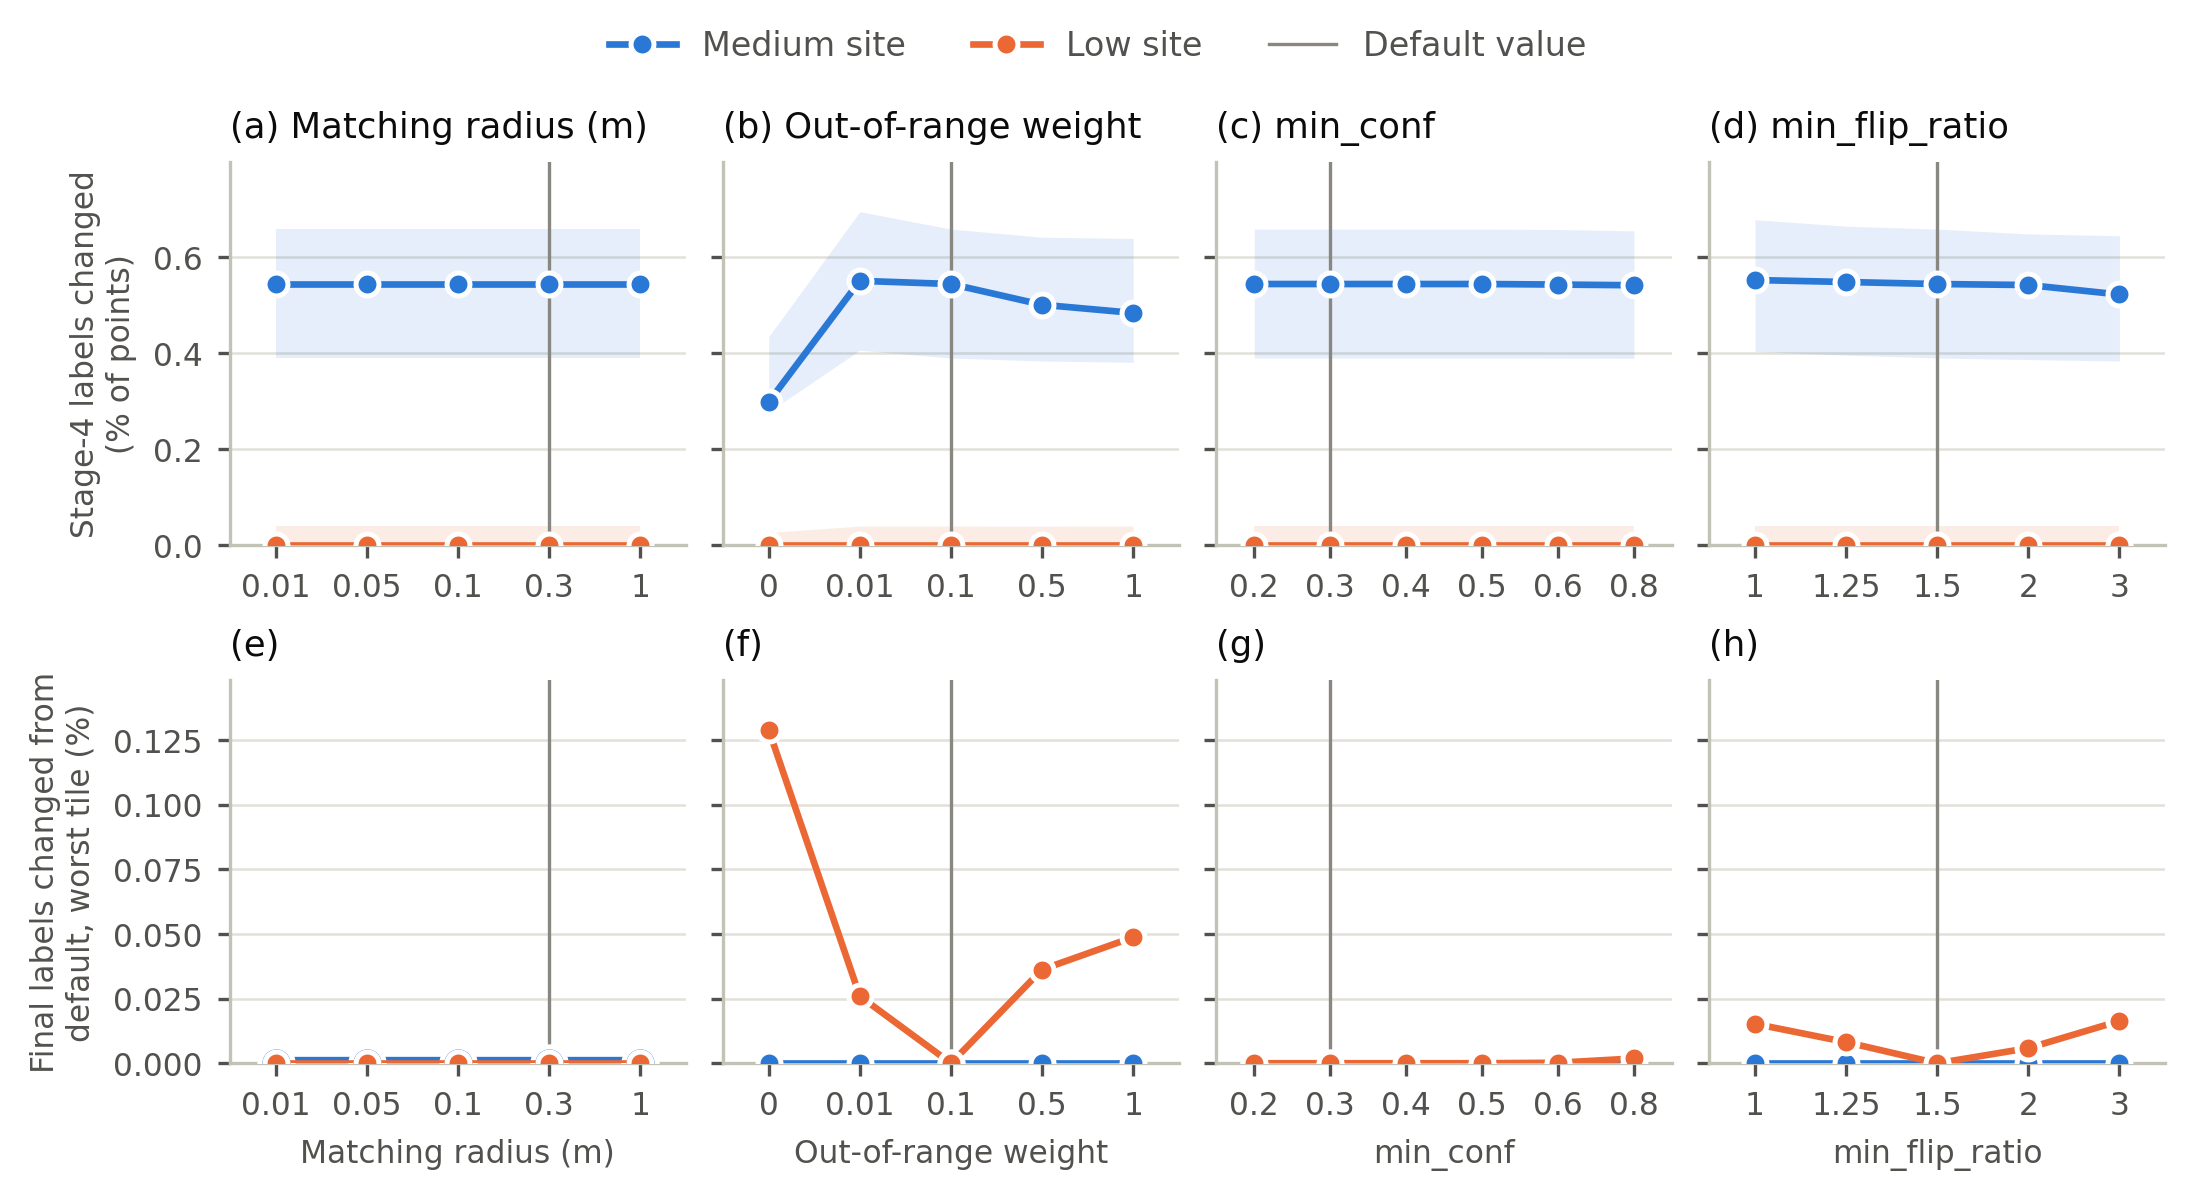

In [13]:
pps.plot_parameter_figure(per_tile, ASSETS / "supplementary_parameter_sensitivity")
display(Image(filename=str(ASSETS / "supplementary_parameter_sensitivity.png")))

Inside Stage 4 at the Medium site, as `mean / median` across tiles. Below the table is the
share of evaluated points that fall under each `min_conf` value, on the worst tile.

In [14]:
display(Markdown(pps.stage4_table(per_tile, "Medium") + "\n\n" + pps.min_conf_extremes(per_tile)))

| Parameter | Value | Stage-4 filled (%) | Stage-4 flipped (%) | Evaluated points below min_conf (%) | Final labels changed (%) |
|---|---:|---:|---:|---:|---:|
| Matching radius (m) | 0.01 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | 0.05 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | 0.1 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | **0.3** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Matching radius (m) | 1 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 0 | 0.278 / 0.265 | 0.062 / 0.037 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 0.01 | 0.471 / 0.425 | 0.071 / 0.042 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | **0.1** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 0.5 | 0.471 / 0.425 | 0.046 / 0.028 | 0.000 / 0.000 | 0.000 / 0.000 |
| Out-of-range weight | 1 | 0.471 / 0.425 | 0.042 / 0.028 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.2 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | **0.3** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.4 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.5 | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_conf | 0.6 | 0.471 / 0.424 | 0.060 / 0.036 | 0.088 / 0.059 | 0.000 / 0.000 |
| min_conf | 0.8 | 0.469 / 0.424 | 0.060 / 0.036 | 0.293 / 0.191 | 0.000 / 0.000 |
| min_flip_ratio | 1 | 0.471 / 0.425 | 0.069 / 0.041 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | 1.25 | 0.471 / 0.425 | 0.063 / 0.038 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | **1.5** | 0.471 / 0.425 | 0.060 / 0.036 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | 2 | 0.471 / 0.425 | 0.054 / 0.034 | 0.000 / 0.000 | 0.000 / 0.000 |
| min_flip_ratio | 3 | 0.471 / 0.425 | 0.047 / 0.032 | 0.000 / 0.000 | 0.000 / 0.000 |

- Medium site, evaluated points below `min_conf` on the worst tile: 0.2: 0.0000%, 0.3: 0.0000%, 0.4: 0.0011%, 0.5: 0.0026%, 0.6: 0.2672%, 0.8: 0.9791%.
- Low site, evaluated points below `min_conf` on the worst tile: 0.2: 0.0000%, 0.3: 0.0000%, 0.4: 0.0000%, 0.5: 0.0000%, 0.6: 1.0095%, 0.8: 4.5839%.

## 4. Draft replies

One reply per review comment, each followed by the figure it cites. The numbers are the ones
generated above; the supplementary figure numbers are placeholders.

### Comment 1 — "the 10 cm voxel size appears empirical; please compare 5, 10, 15, 20, 25 cm"

> We have added this comparison as **Supplementary Figure S1**. The complete workflow was run at
> 5, 10, 15, 20 and 25 cm on all 30 reference tiles.
>
> We should first clarify what this parameter is. The voxel size governs the **2D→3D label
> transfer** used to build training labels; it is not the input resolution of the segmentation
> models, which consume the labelled points directly and apply their own internal voxelisation.
> It controls how far a class annotated in 2D is propagated to neighbouring lidar returns.
>
> Because the labelled points are the lidar returns themselves, each already carrying the class
> of the 5 cm label cell beneath it, voxel size has almost no effect on returns *inside* the
> labelled footprints: at every size and on every tile, at least 98.8% (Medium) and 97.7% (Low)
> kept their 2D class. What it controls is extension beyond those footprints, and agreement with
> the 2D labels therefore falls monotonically as the voxel grows (mIoU 0.79 → 0.65 → 0.45 at the
> Medium site for 5, 10 and 25 cm; 0.79 → 0.69 → 0.53 at the Low site). We have revised 3.2.2 to
> state plainly that this is a monotonic trade-off and that the comparison does not identify an
> optimum: because the 2D annotation is both the input and the reference, any extension is scored
> as disagreement, and no independent 3D reference exists for these sites.
>
> We therefore justify 10 cm on **survey point density** rather than on agreement, which makes
> the choice a property of the data rather than a tuned value. The merge can only act where a
> voxel contains more than one labelled return, so the relevant scale is the mean spacing of the
> labelled returns: 4.5 cm at the Medium site and 5.6 cm at the Low site (493 and 321 labelled
> returns m⁻²). A 5 cm voxel is about one spacing wide — narrower than the spacing at the Low
> site — and accordingly holds a median of one labelled return, with 67% (Medium) and 48% (Low)
> of voxels holding exactly one; the merge then reduces to projecting the 2D raster onto the
> points. At 10 cm the voxel is roughly two spacings, the median rises to 2.3 and 5.0 returns and
> single-occupancy falls to 34% and 18%, while labels still reach at most one voxel beyond their
> footprint and fewer than 1% of voxels mix classes. Above 10 cm voxels approach the size of the
> mapped features (median polygon ≈28 cm across) and mixed-class voxels grow steadily, to 1.6%
> (Medium) and 3.8% (Low) at 25 cm. Expressed as a rule, the voxel should be about twice the mean
> spacing of the labelled returns, which scales as the inverse square root of survey density and
> so transfers to surveys of different point density.
>
> Two limitations should be stated. First, this spacing is a plan-view average, and return
> density varies strongly with height (**Supplementary Figure S3**): above 3 m the Medium site
> carries only ~8 labelled returns m⁻², so in the upper canopy a 10 cm voxel usually holds a
> single labelled return and the transfer is correspondingly weaker for tall vegetation. The
> chosen size satisfies the two-spacing criterion through the understorey, where the great
> majority of labelled returns lie, but not throughout the profile; a height-varying voxel would
> follow the density more closely and is a natural extension. Second, the additional returns
> labelled by enlarging the voxel lie almost entirely (99–100%) on cells the 2D annotation leaves
> unlabelled, and without 3D reference data we cannot determine whether these represent spurious
> spread or genuine recovery of a feature's extent beyond its plan-view outline.


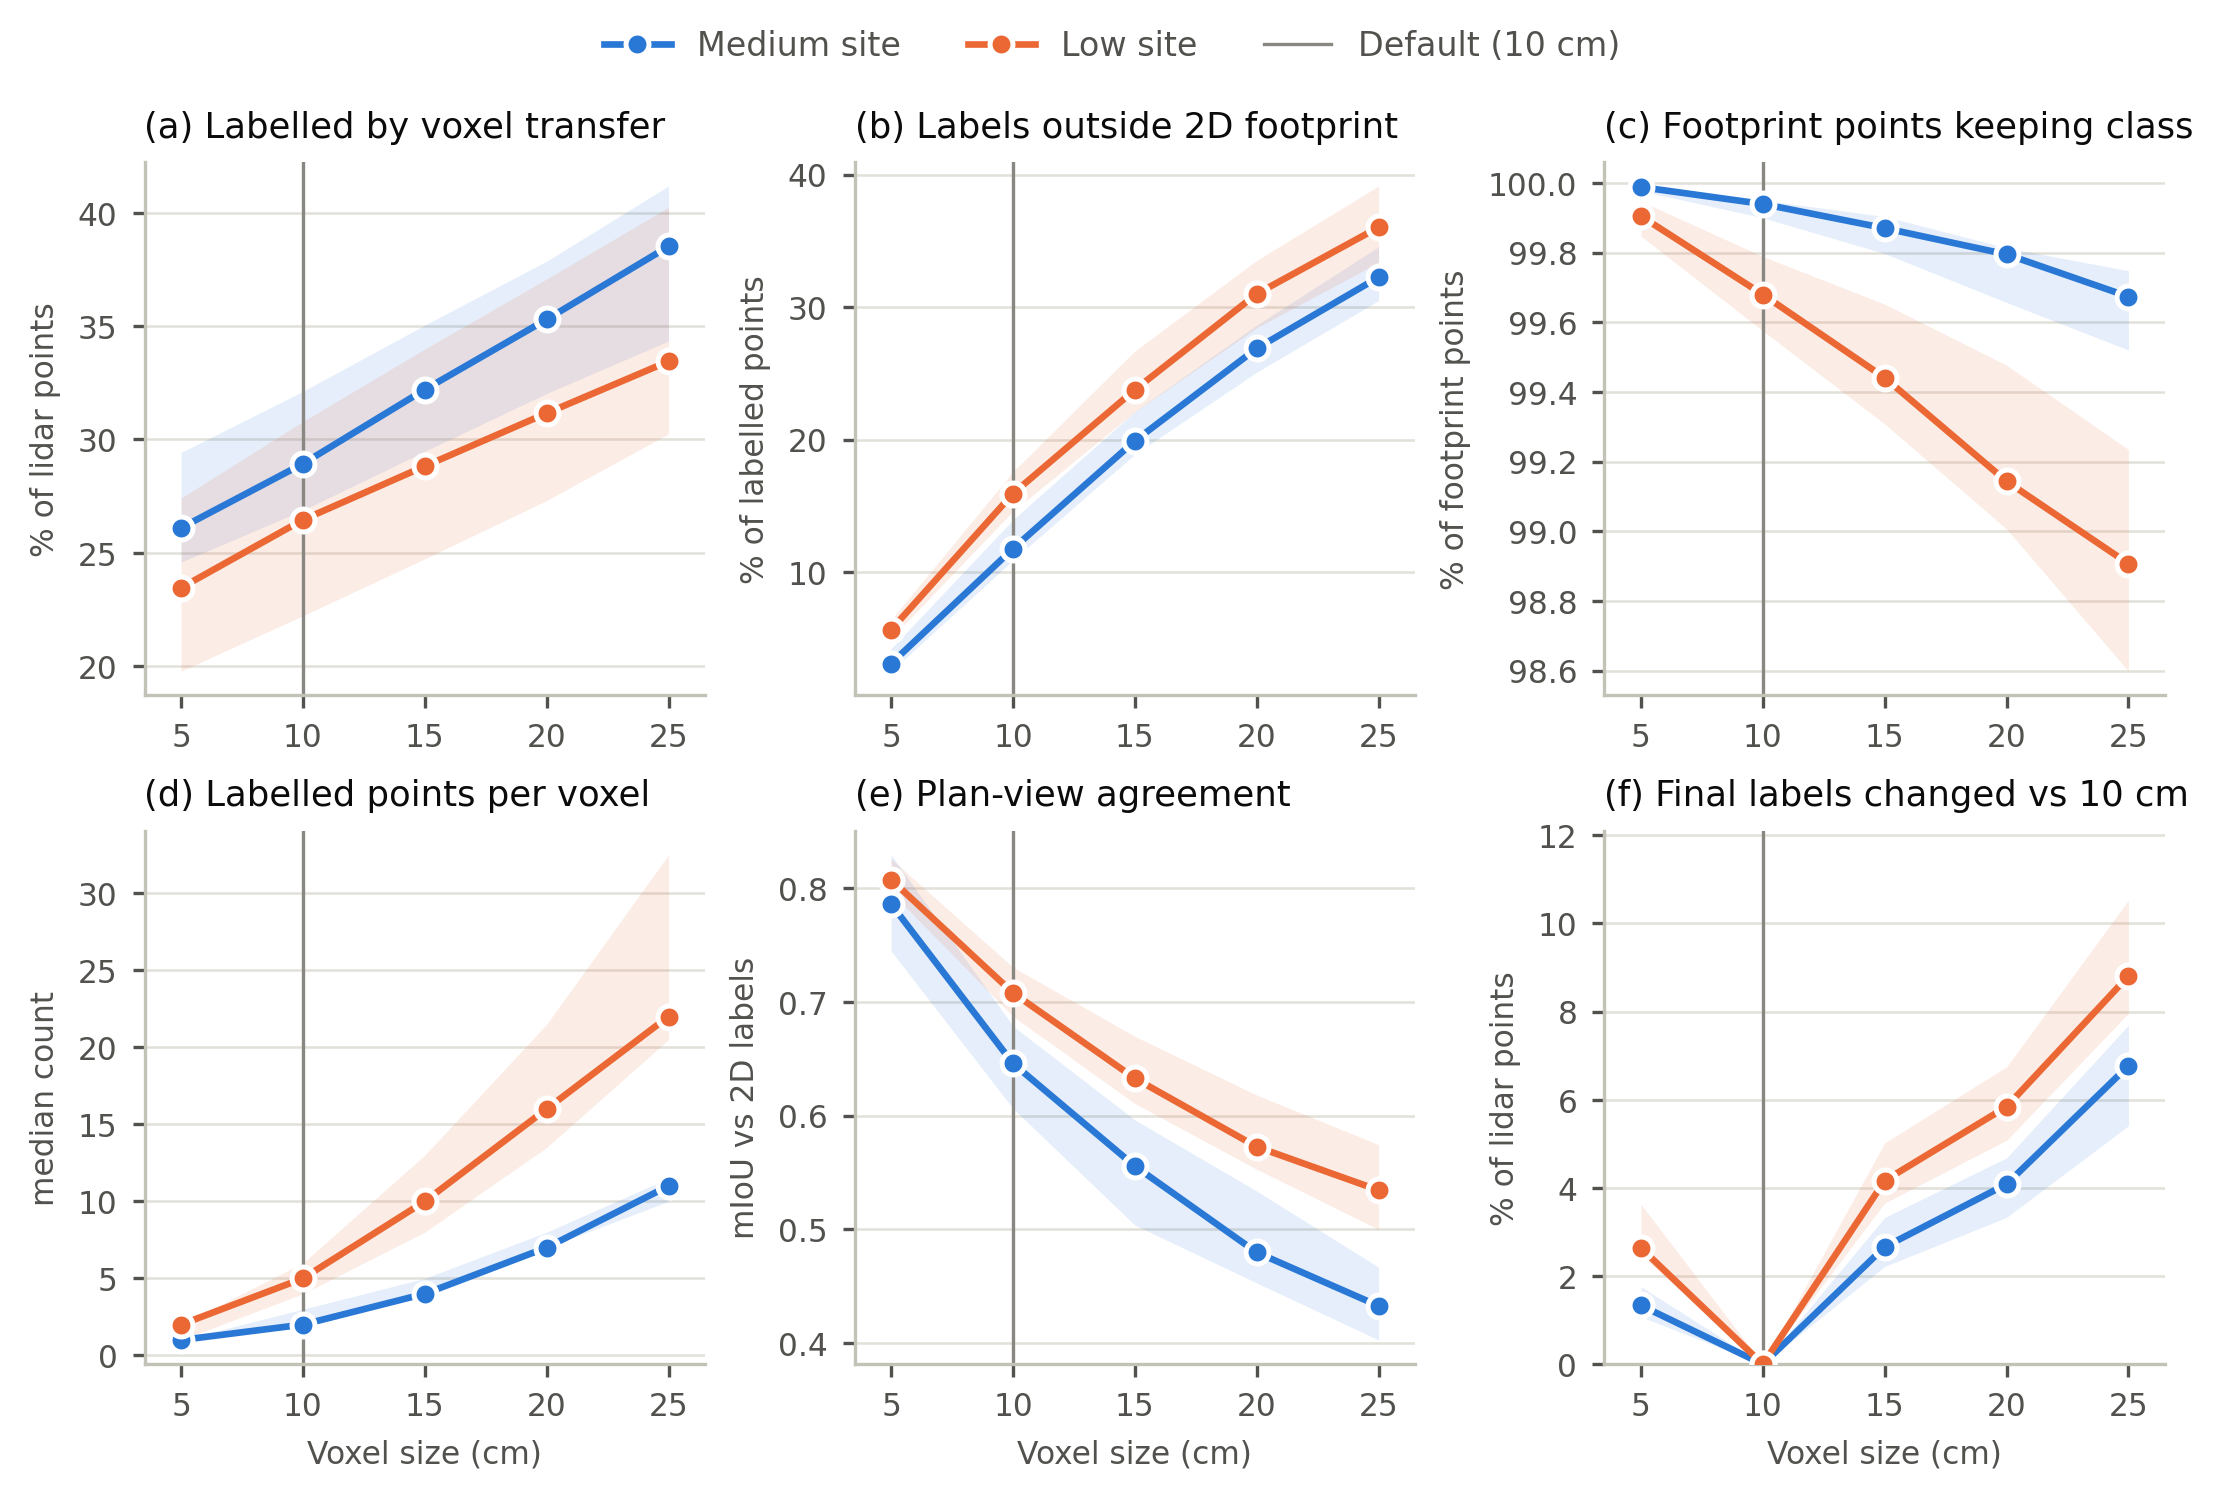

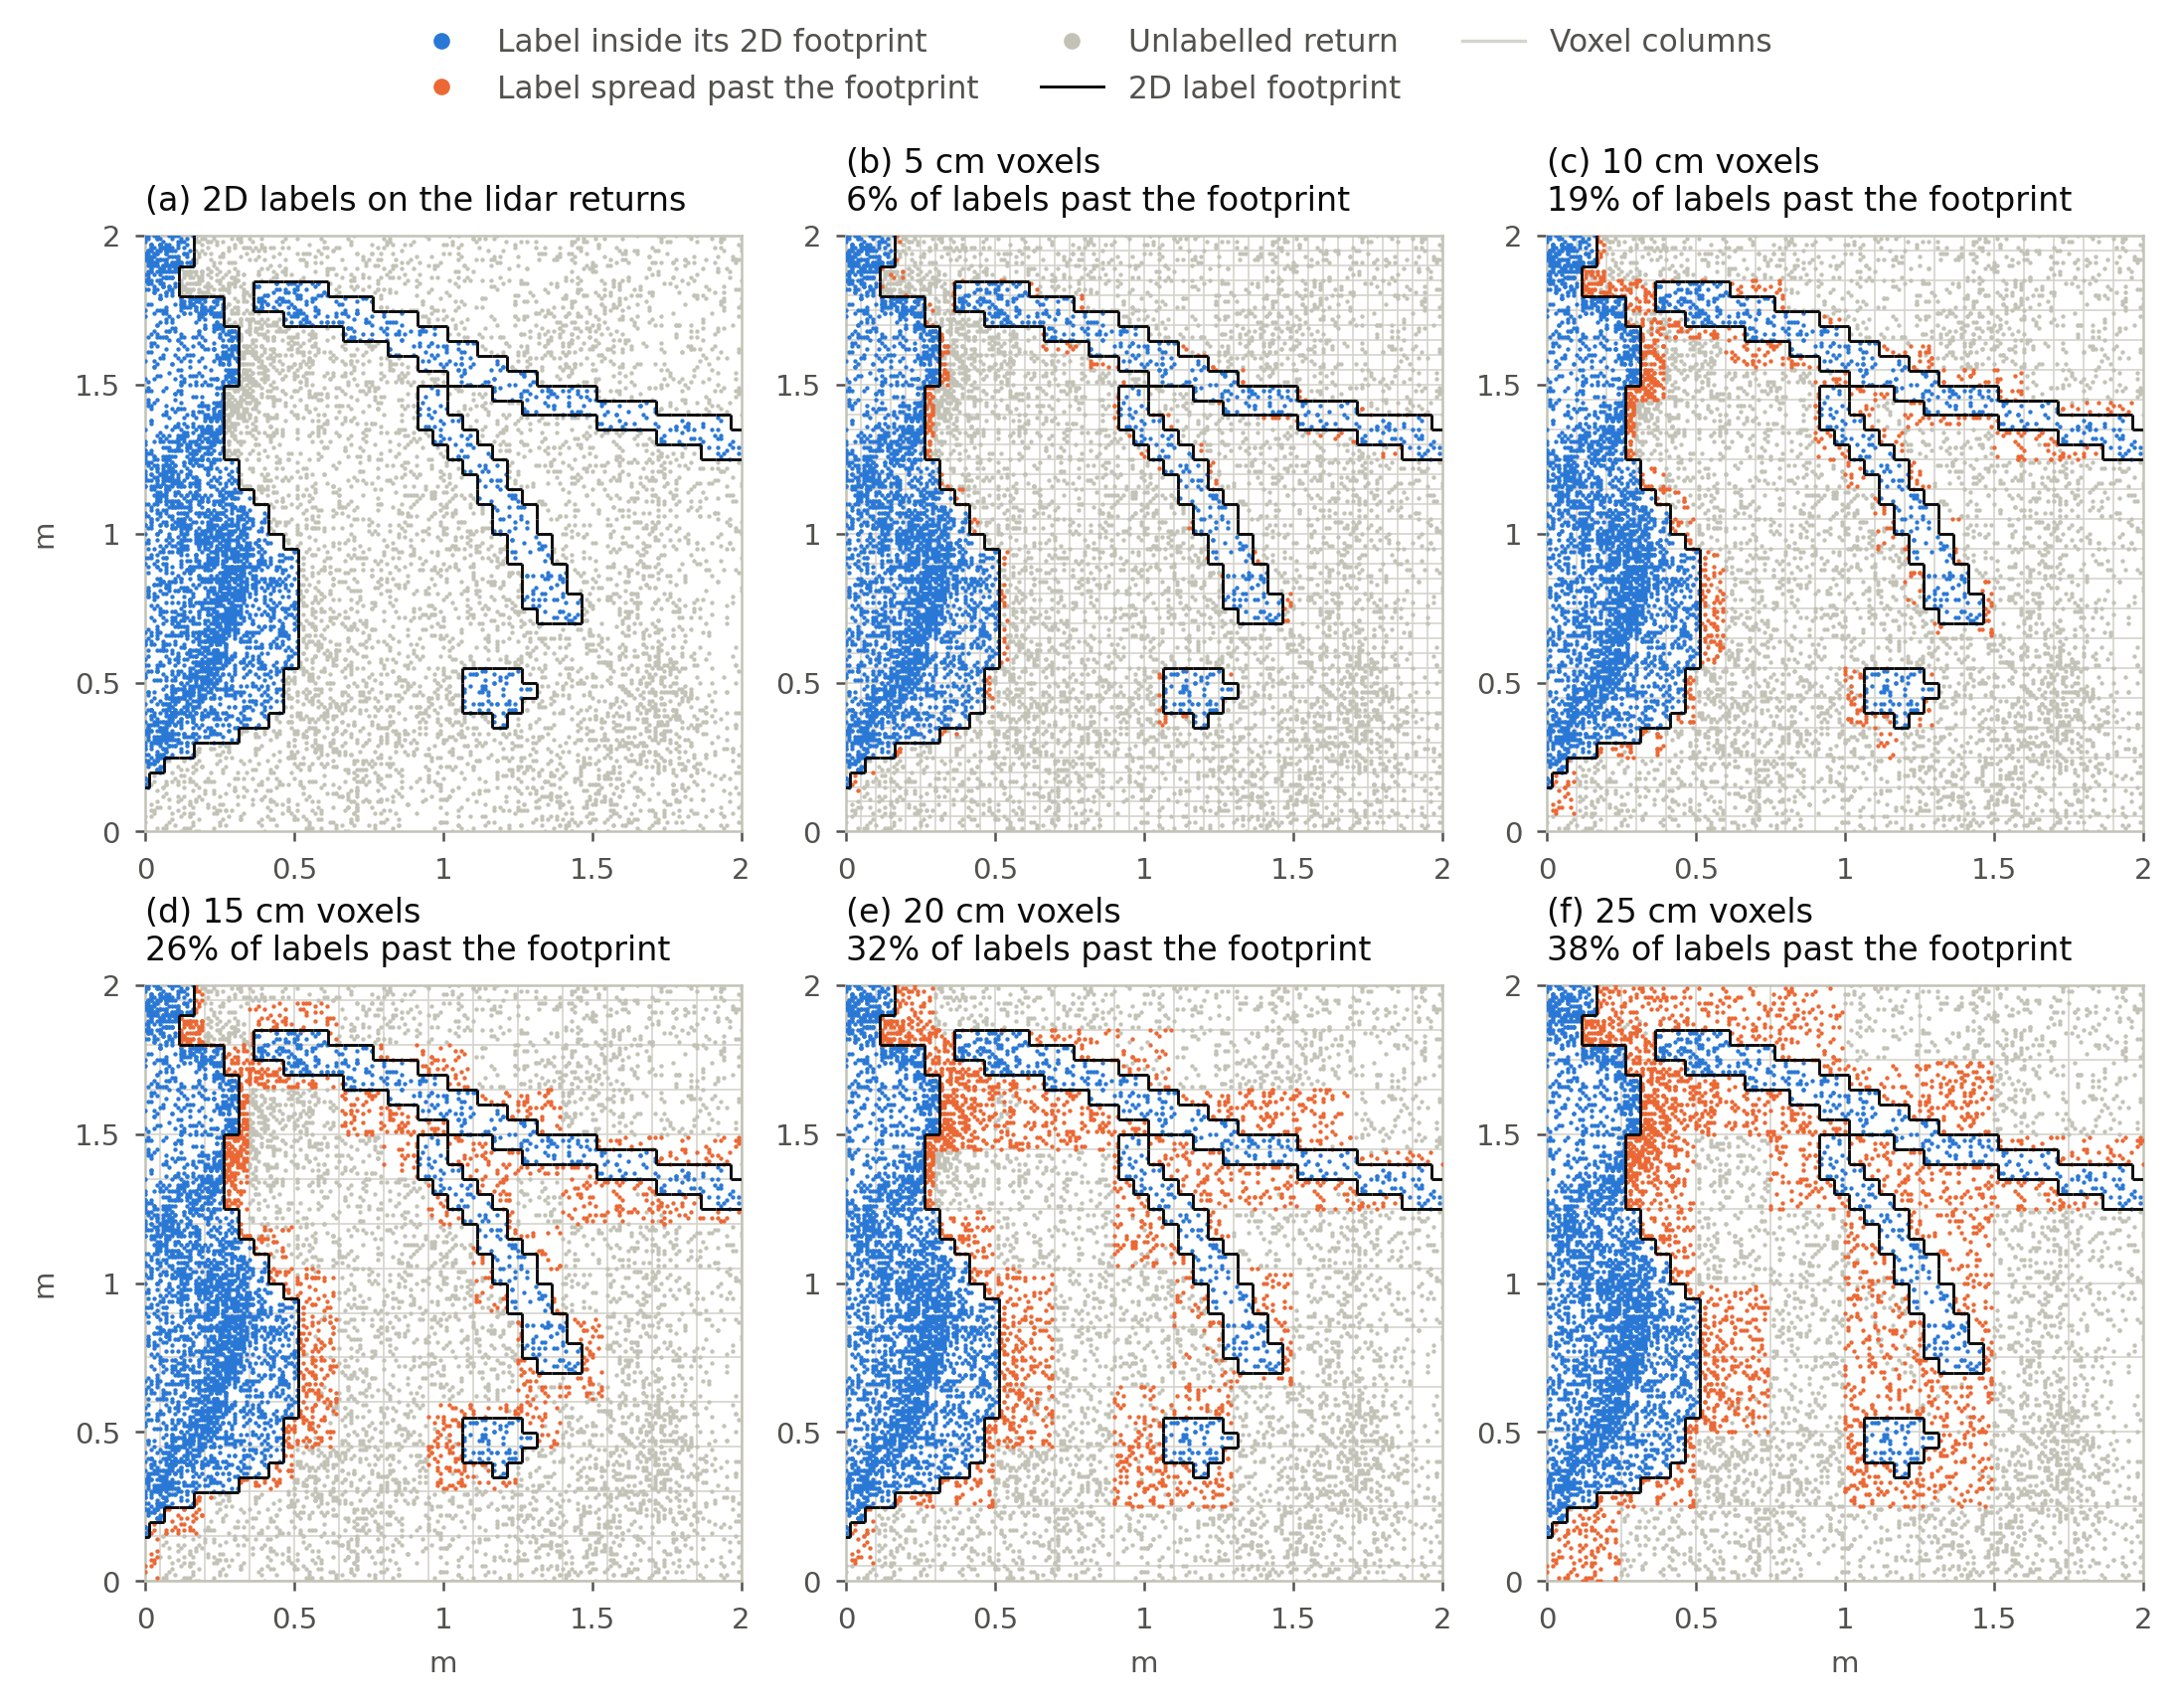

In [15]:
display(Image(filename=str(ASSETS / "supplementary_voxel_size_sensitivity.png")))
display(Image(filename=str(transfer_figure)))


### Comment 2 — "why was the 0.30 m matching radius selected?"

> The radius caps the nearest-neighbour search that gives each labelled point its height above
> ground when the class height ranges are estimated (Stage 1). In our data the labelled points
> **are** the lidar returns, so every one has an exact counterpart in the height-normalised cloud
> and was matched at **0.00 m on all 30 tiles**; no point on any tile lay beyond the radius.
>
> Its value therefore does not affect the results: radii of 0.01, 0.05, 0.10, 0.30 and 1.00 m
> produced **identical labels on every tile** (0.0000% of points changed; **Supplementary Figure
> S2**, panels a and e). It is a guard against unmatched points that this dataset never triggers,
> and we have restated it as such.


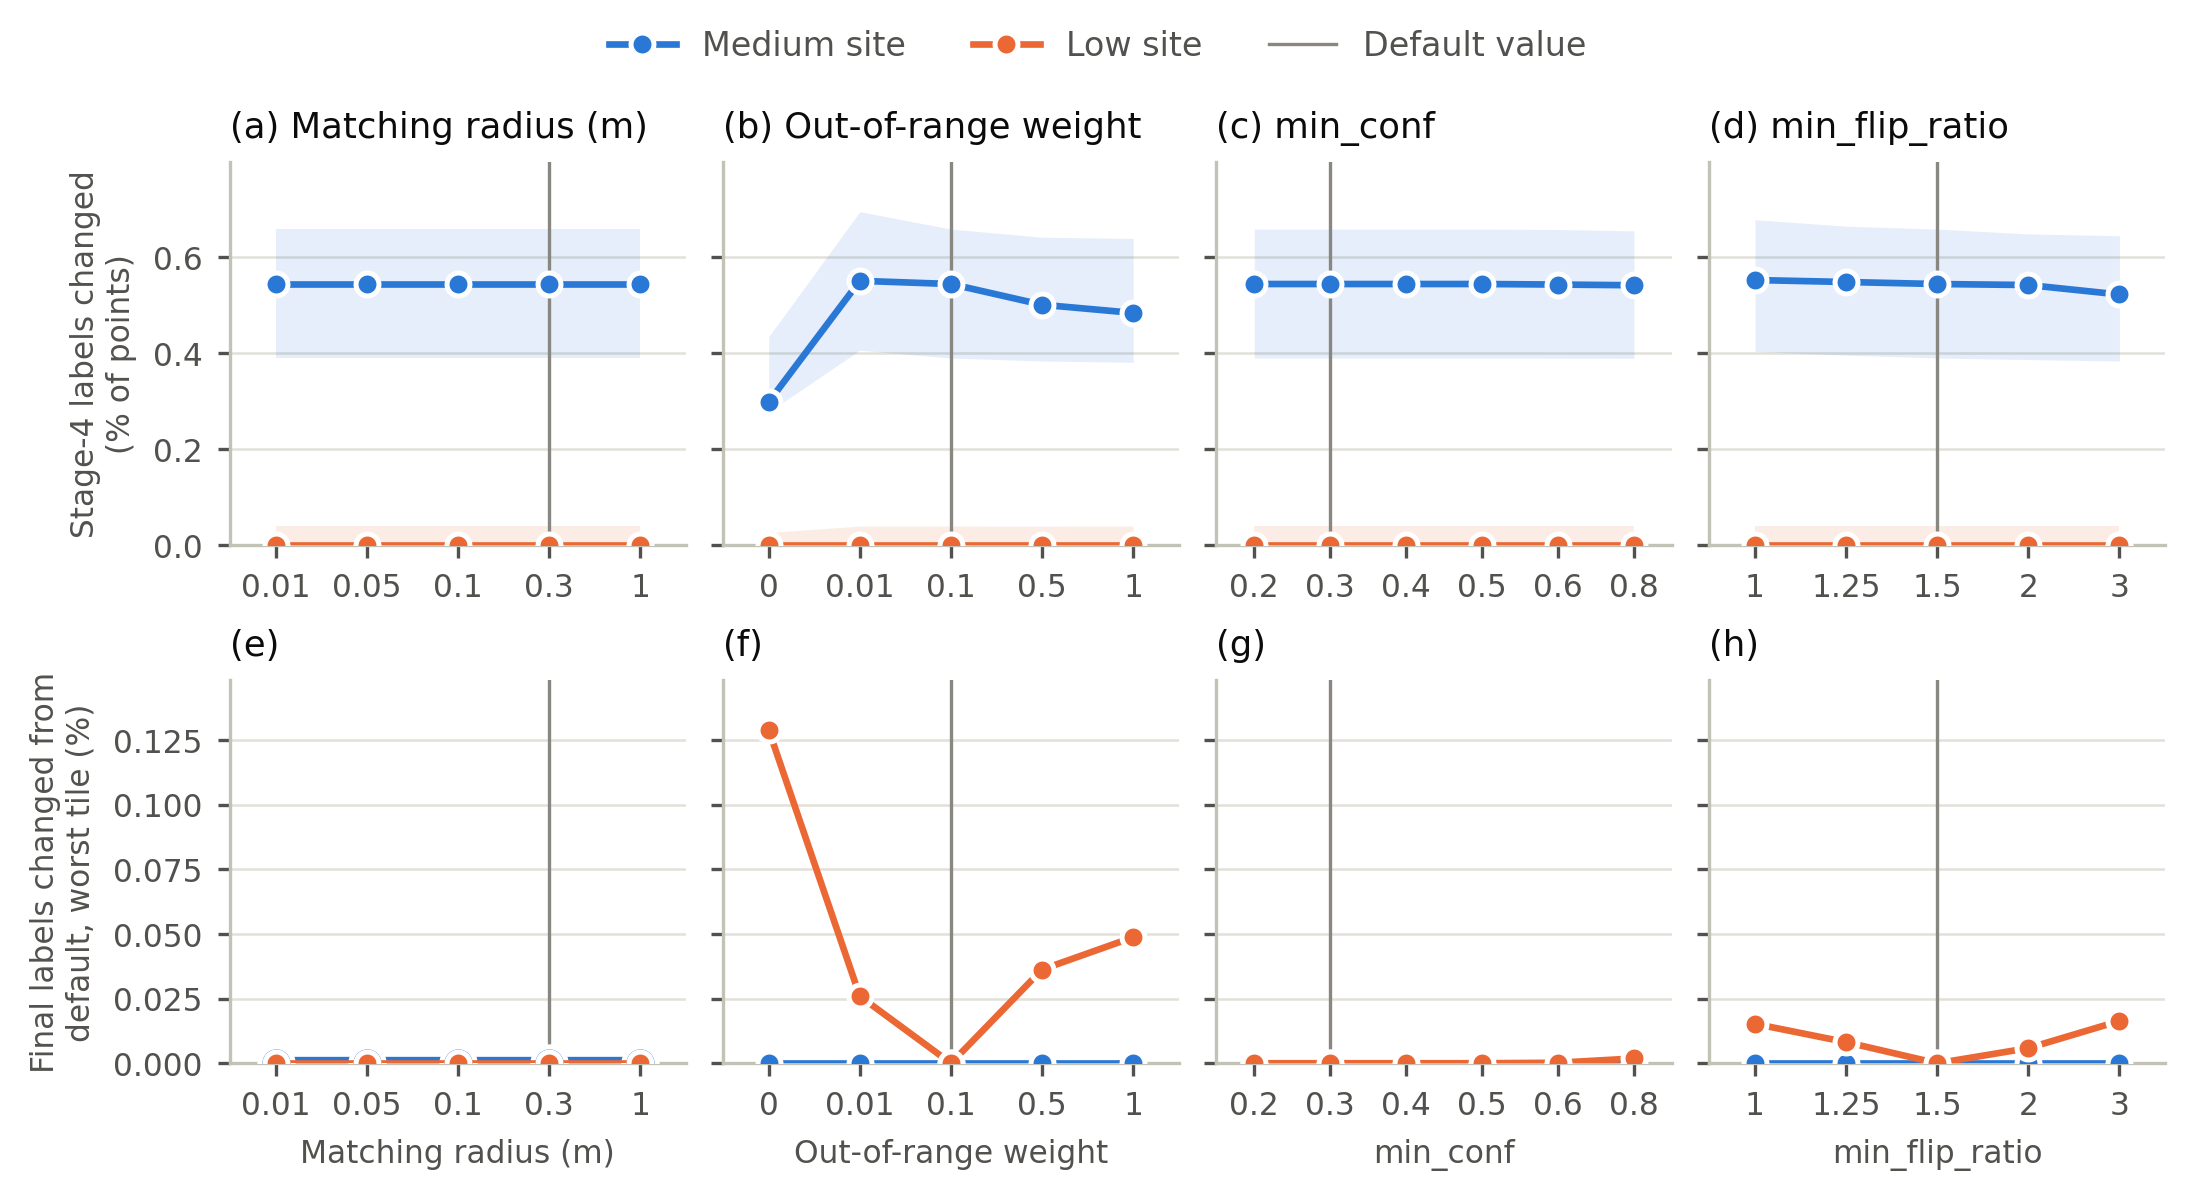

In [16]:
display(Image(filename=str(ASSETS / "supplementary_parameter_sensitivity.png")))


### Comment 3 — "why were voxel size, weighting (1, 0.1), confidence threshold and flip ratio set at these values?"

> **Voxel size (10 cm)** — as in our reply above, with Supplementary Figure S1.
>
> **Height-prior weights (1, 0.1)** — these form a *soft* height prior in the crown refinement
> (Stage 4). A class's share of a polar bin is kept in full when the point lies inside that
> class's 15th–85th percentile height range, and multiplied by 0.1 when it does not. The weighted
> shares are renormalised, so **only their ratio matters**: a class outside its height range must
> be ten times as frequent in the bin to be assigned. The weight is not 0 because each range
> excludes 30% of that class's own points by construction, so a hard veto would forbid those
> labels — it removed 41% of Stage-4 assignments in our tests. A weight of 1 disables the prior.
>
> **Confidence threshold (0.3)** — governs only whether Stage 4 labels a point that the voxel
> transfer left unlabelled. The most probable of *k* classes always scores at least 1/*k*, so 0.3
> accepts any bin holding up to three classes and rejects only near-ties among four or five. It
> never bound: Stage-4 probabilities averaged 0.998 and no evaluated point on any tile fell below
> 0.3.
>
> **Flip ratio (1.5)** — sets how much stronger the evidence must be to overturn a label inherited
> from the 2D annotation. In a two-class bin this is a 60:40 majority rather than a bare one, so
> labels are not reversed on near-ties.
>
> Across every value tested, the final labels changed by at most **0.13% of points** at either
> site (**Supplementary Figure S2**, panels b–d and f–h).


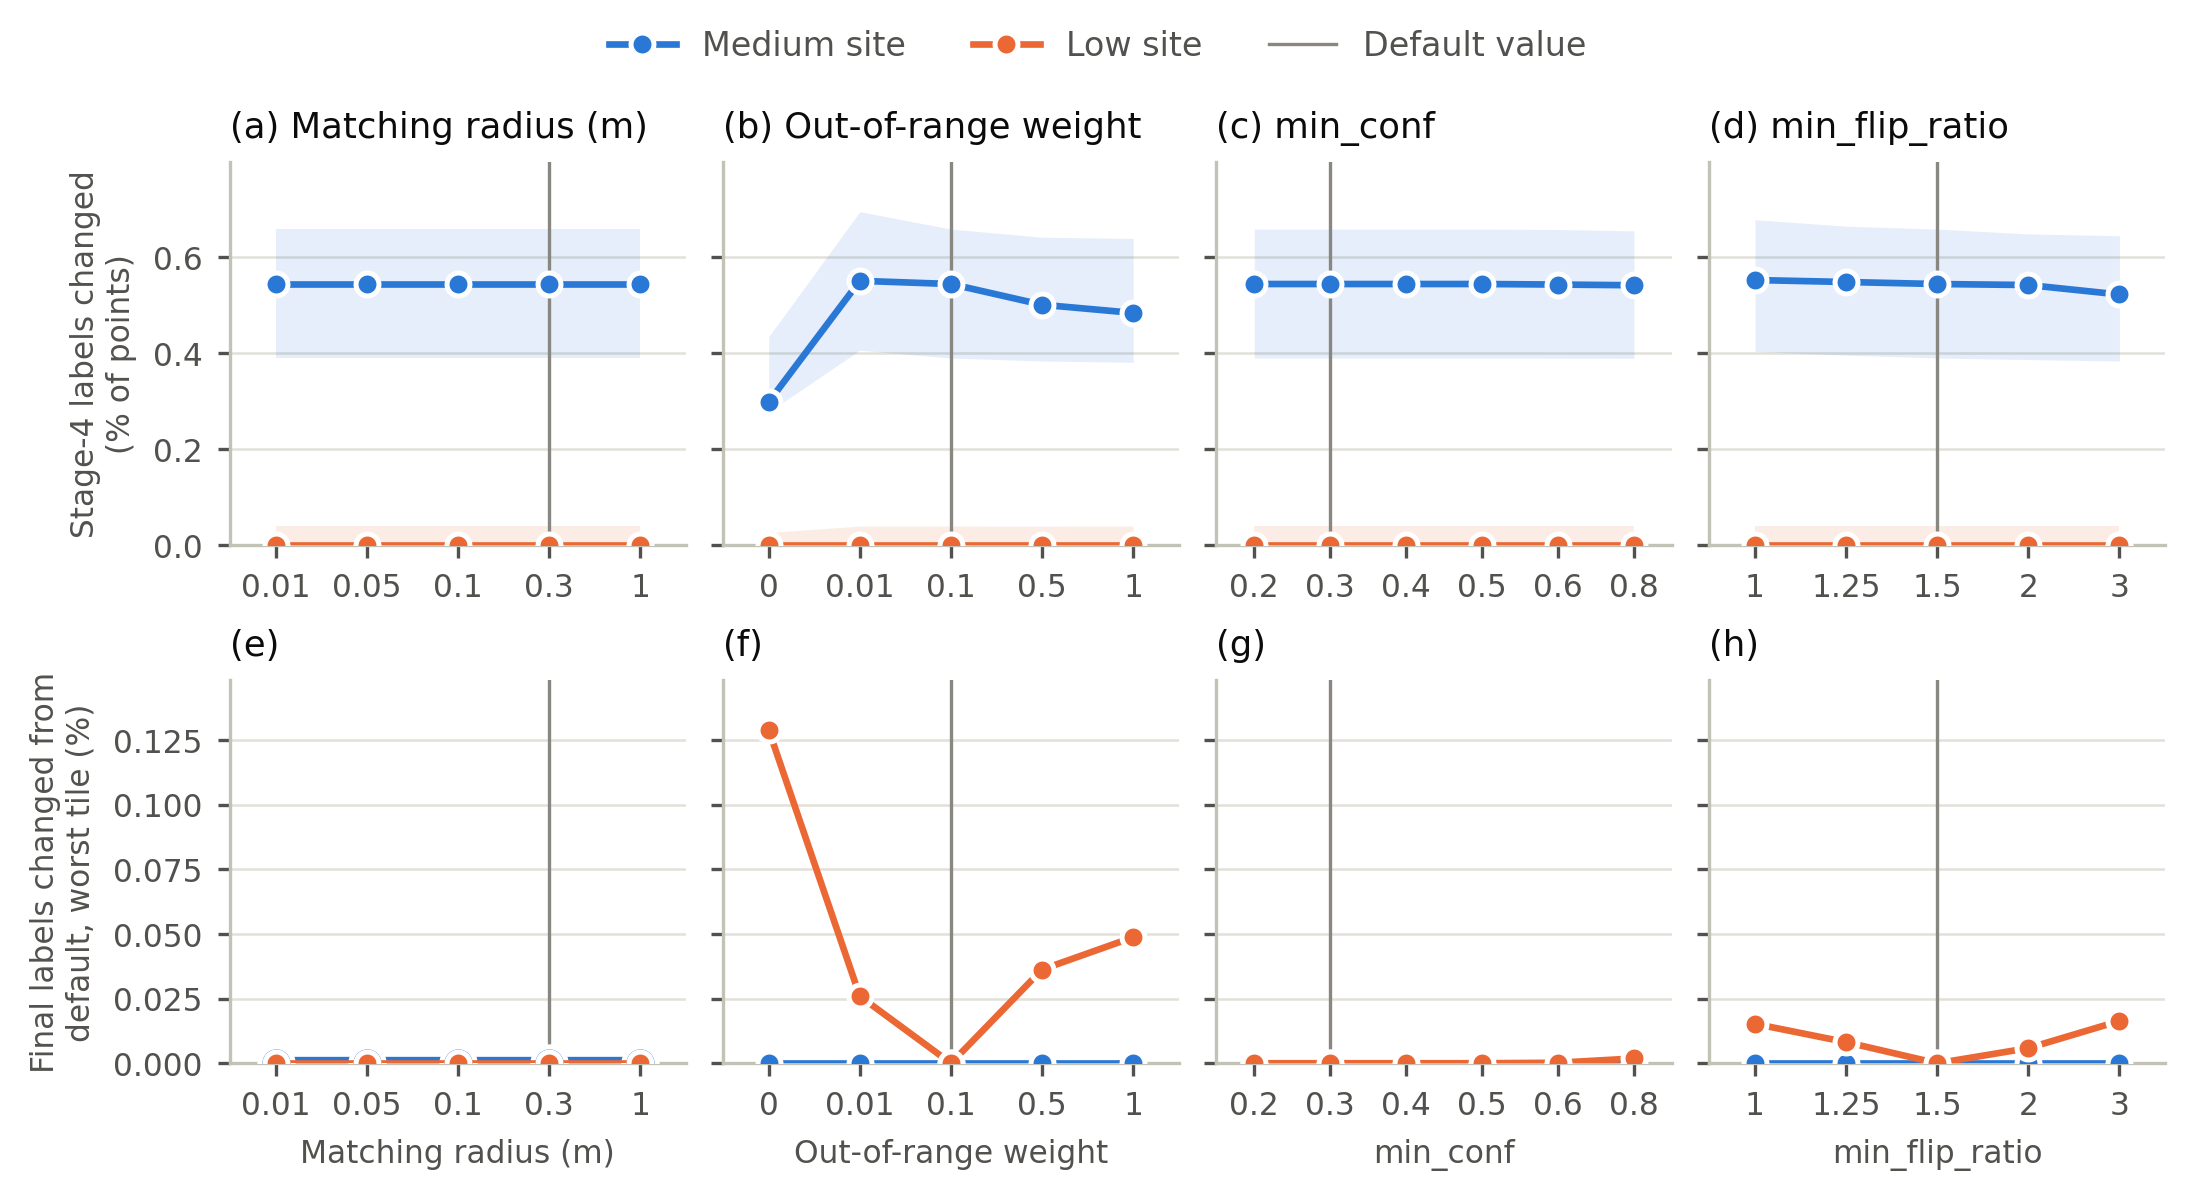

| Parameter | Default | What it decides | Values tested | Medium: largest change (%) | Low: largest change (%) |
|---|---:|---|---|---:|---:|
| Voxel size | 10 cm | how far a 2D label extends to neighbouring returns | 5, 10, 15, 20, 25 | 9.24 | 16.28 |
| Matching radius | 0.3 m | how far a point may look for its height above ground | 0.01, 0.05, 0.1, 0.3, 1 | 0.00 | 0.00 |
| Out-of-range weight | 0.1 | how strongly a class outside its height range is penalised | 1, 0.5, 0.1, 0.01, 0 | 0.00 | 0.13 |
| min_conf | 0.3 | whether an unlabelled point inside a crown is filled | 0.2, 0.3, 0.4, 0.5, 0.6, 0.8 | 0.00 | 0.00 |
| min_flip_ratio | 1.5 | whether an existing label is overturned | 1, 1.25, 1.5, 2, 3 | 0.00 | 0.02 |

In [17]:
display(Image(filename=str(ASSETS / "supplementary_parameter_sensitivity.png")))
display(Markdown(pps.answer_table(per_tile)))


## 5. Regenerating

```bash
cd phase_4_3D_lidar_prep/step_3_structure_class
python parameter_sensitivity.py --workers 16 --output-dir assets/parameter_sensitivity
python plot_parameter_sensitivity.py --csv assets/parameter_sensitivity/parameter_sensitivity_per_tile.csv
```

Then rerun this notebook; it redraws both voxel figures from the lidar tiles. The README's
**Reproduce** section covers `--data-root` and running from a local copy of the inputs.
